<a href="https://colab.research.google.com/github/investor101777/investor101777.github.io/blob/main/HDA_ProcessConditions_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study — Understanding Process Conditions with Plant Data and Machine Learning
### CED1 · Chapter 6 · Toluene hydrodealkylation (HDA), reactor R-101 and high-pressure flash V-102

**You are the new process engineer.** The plant manager has 18 months of operating data from the reactor and flash section and two questions:

1. *Which process conditions really control benzene production and benzene losses?*
2. *Production wants to run R-101 hotter to make more benzene. A machine-learning model trained on the historian data says this is a good idea. Is it?*

Your job is to answer both with evidence from **your own dataset**. Every student has a different dataset generated from the same physics, with different numbers, dates and data problems. Answers copied from another student or from a generic AI answer will not match your data.

---
#### Learning outcomes
By the end of this notebook you will be able to:
1. **Audit** plant data before modelling: units, frozen sensors, analyser errors, using the event log as evidence.
2. **Connect conditions to physics**: Arrhenius temperature dependence, residence time, H₂ partial pressure, Raoult's law at the flash.
3. **Build and judge ML models**: time-based validation, feature importance, confounded variables, extrapolation.
4. **Check a recommendation against conditions of special concern** (Ch. 6 operating window, design limits, process conditions matrix).

#### How this notebook works
* Run the cells **in order** (Runtime → Run all works only after you fill in the audit parameters in Step 3).
* 📘 cells explain the method. ▶️ cells are code you run. ✏️ cells are **your answers** (graded).
* ❓ **Questions Q1–Q7 are not answered for you.** Each one asks for numbers, timestamps or plots from **your** outputs. Quote them exactly and say which cell produced them.
* Estimated time: 3 hours (lab) + report.

### 📘 Process background (read before you start)

**Main reaction** (thermal, no catalyst):  C₇H₈ + H₂ → C₆H₆ + CH₄  ΔH ≈ −42 kJ/mol, **Δn = 0**

**Side reaction:** 2 C₆H₆ ⇌ C₁₂H₁₀ (diphenyl) + H₂  — lowers selectivity, favoured by high conversion, high temperature and low H₂.
Above about 690 °C, **hydrocracking** of aromatics to methane becomes significant.

| Tag | Meaning | Units |
|---|---|---|
| `F_tol_kmolh` | toluene (fresh + recycle) to R-101 | kmol/h |
| `H2_tol_ratio` | H₂ : toluene molar ratio at reactor inlet | – |
| `T_in_C`, `T_out_C` | R-101 inlet / outlet temperature (TT-101, TT-102) | °C |
| `P_R_barg` | R-101 pressure (PT-101) | barg |
| `X_tol_AT201` | toluene conversion from online analyser AT-201 | – |
| `S_benz` | selectivity: mol benzene formed / mol toluene converted | – |
| `benzene_kmolh` | benzene formed in R-101 = F·X·S | kmol/h |
| `T_cw_C` | cooling-water supply temperature | °C |
| `T_flash_C_TT104`, `P_flash_barg` | V-102 temperature (TT-104), pressure (PT-104) | °C, barg |
| `benz_loss_purge_kmolh` | benzene lost with the purge gas | kmol/h |
| `H101_duty_kW` | fired-heater H-101 duty | kW |

#### Plant data sheet (use it — the ML model does not know it)
| Item | Limit |
|---|---|
| R-101 volume | 40 m³ (adiabatic, plug flow) |
| R-101 design temperature (outlet) | **700 °C** |
| R-101 / V-102 design pressure | 28 barg / 27 barg |
| H-101 maximum firing duty | **3 500 kW** |
| Cooling water | from cooling tower; supply temperature follows the season |
| Benzene Antoine constants (mmHg, °C) | A = 6.90565, B = 1211.033, C = 220.79 |

## Step 0 · Setup and data loading
▶️ Set your **student ID** exactly as on your data files (`hda_ops_<ID>.csv`, `hda_events_<ID>.csv`). In Colab, the cell asks you to upload both files the first time.

In [ ]:
STUDENT_ID = "230144"   # I am doing #30

import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance, partial_dependence
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import calendar

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

ops_file, ev_file = f"hda_ops_{STUDENT_ID}.csv", f"hda_events_{STUDENT_ID}.csv"
if not (os.path.exists(ops_file) and os.path.exists(ev_file)):
    try:
        from google.colab import files
        print("Upload", ops_file, "and", ev_file); files.upload()
    except ImportError:
        raise FileNotFoundError("Put the two CSV files next to this notebook.")
raw = pd.read_csv(ops_file, parse_dates=["timestamp"])
events = pd.read_csv(ev_file, parse_dates=["timestamp"])
print(raw.shape, "rows x columns  |", raw.timestamp.min(), "→", raw.timestamp.max())

Upload hda_ops_230144.csv and hda_events_230144.csv


Saving hda_events_230144.csv to hda_events_230144.csv
Saving hda_ops_230144.csv to hda_ops_230144.csv
(3283, 14) rows x columns  | 2025-01-01 00:00:00 → 2026-07-02 00:00:00


## Step 1 · First look at the data
📘 Before any model, look at ranges. A process variable outside its physical range is a **data** problem, not a process insight. Compare each min/max with the data sheet and with Ch. 6 typical ranges.

In [ ]:
display(raw.head())
display(raw.describe().T.round(3))
print("Missing values per column:\n", raw.isna().sum()[raw.isna().sum() > 0])
display(events)

,timestamp,F_tol_kmolh,H2_tol_ratio,T_in_C,P_R_barg,T_out_C,X_tol_AT201,S_benz,benzene_kmolh,T_cw_C,T_flash_C_TT104,P_flash_barg,benz_loss_purge_kmolh,H101_duty_kW
0,2025-01-01 00:00:00,123.71,4.648,604.3,24.65,649.9,0.7712,0.9807,93.56,29.8,37.8,23.22,0.3898,2429
1,2025-01-01 04:00:00,121.74,4.564,603.4,24.12,649.2,0.7536,0.9839,90.26,28.8,36.6,22.73,0.3421,2349
2,2025-01-01 08:00:00,121.40,4.336,603.0,24.19,652.7,0.7844,0.9835,93.65,29.8,37.0,22.80,0.3426,2245
3,2025-01-01 12:00:00,122.83,4.024,604.9,23.69,660.9,0.8351,0.9753,100.04,28.7,37.0,22.33,0.3431,2149
4,2025-01-01 16:00:00,121.56,3.937,600.4,23.62,654.6,0.8067,0.9793,96.03,29.1,36.8,22.19,0.3347,2065


,count,mean,min,25%,50%,75%,max,std
timestamp,3283,2025-10-01 12:00:00,2025-01-01 00:00:00,2025-05-17 18:00:00,2025-10-01 12:00:00,2026-02-15 06:00:00,2026-07-02 00:00:00,NaN
F_tol_kmolh,3283.0,124.543415,104.72,118.94,124.08,130.36,144.0,7.264939
H2_tol_ratio,3283.0,4.714934,3.019,4.309,4.705,5.1345,6.788,0.612757
T_in_C,3283.0,605.6841,585.7,600.5,605.0,609.7,670.6,8.939529
P_R_barg,3283.0,45.229982,22.35,24.27,24.85,25.43,386.2,80.873237
T_out_C,3270.0,651.724648,606.8,641.3,651.3,661.775,738.5,16.334809
X_tol_AT201,3283.0,0.77338,0.4099,0.704,0.7799,0.8571,1.0,0.109743
S_benz,3270.0,0.976866,0.4866,0.9752,0.9839,0.9897,1.0,0.042413
benzene_kmolh,3283.0,93.411419,50.82,86.045,94.61,101.87,121.75,12.297216
T_cw_C,3283.0,24.367408,15.8,19.1,22.9,29.4,35.7,5.70417


Missing values per column:
 T_out_C                  13
S_benz                   13
benz_loss_purge_kmolh    13
dtype: int64


,event_id,timestamp,category,entry
0,E01,2025-02-13 16:00:00,Maintenance,P-101B pump seal replaced; P-101A in service
1,E02,2025-06-21 23:00:00,Maintenance,TT-104 transmitter replaced after operator rep...
2,E03,2025-07-11 12:00:00,Operations,Fresh toluene tank switched (T-02 to T-03)
3,E04,2025-09-28 13:00:00,Operations,Production request: trial at higher reactor in...
4,E05,2025-10-06 05:00:00,Operations,Trial stopped: TAH on R-101 outlet; H-101 tube...
5,E06,2025-11-08 20:00:00,Safety,"Quarterly relief-valve inspection, no findings"
6,E07,2025-12-21 02:00:00,DCS,Historian server migrated to new DCS; tags PT-...
7,E08,2026-01-23 09:00:00,Instrumentation,Historian configuration audit completed; engin...
8,E09,2026-05-02 17:00:00,Laboratory,AT-201 recalibrated against lab GC; analyser r...
9,E10,2026-05-24 20:00:00,Laboratory,Benzene product purity 99.92 % (monthly spec c...


## Step 2 · Data audit: time series with the event log
📘 **Why plot against time?** Plant data are a time series. Instrument faults, unit changes and campaigns appear as *steps, flat lines and spikes* that a scatter plot or `describe()` hides. The dashed lines are event-log entries (labelled E01, E02, …).

▶️ Run the cell and study every panel.

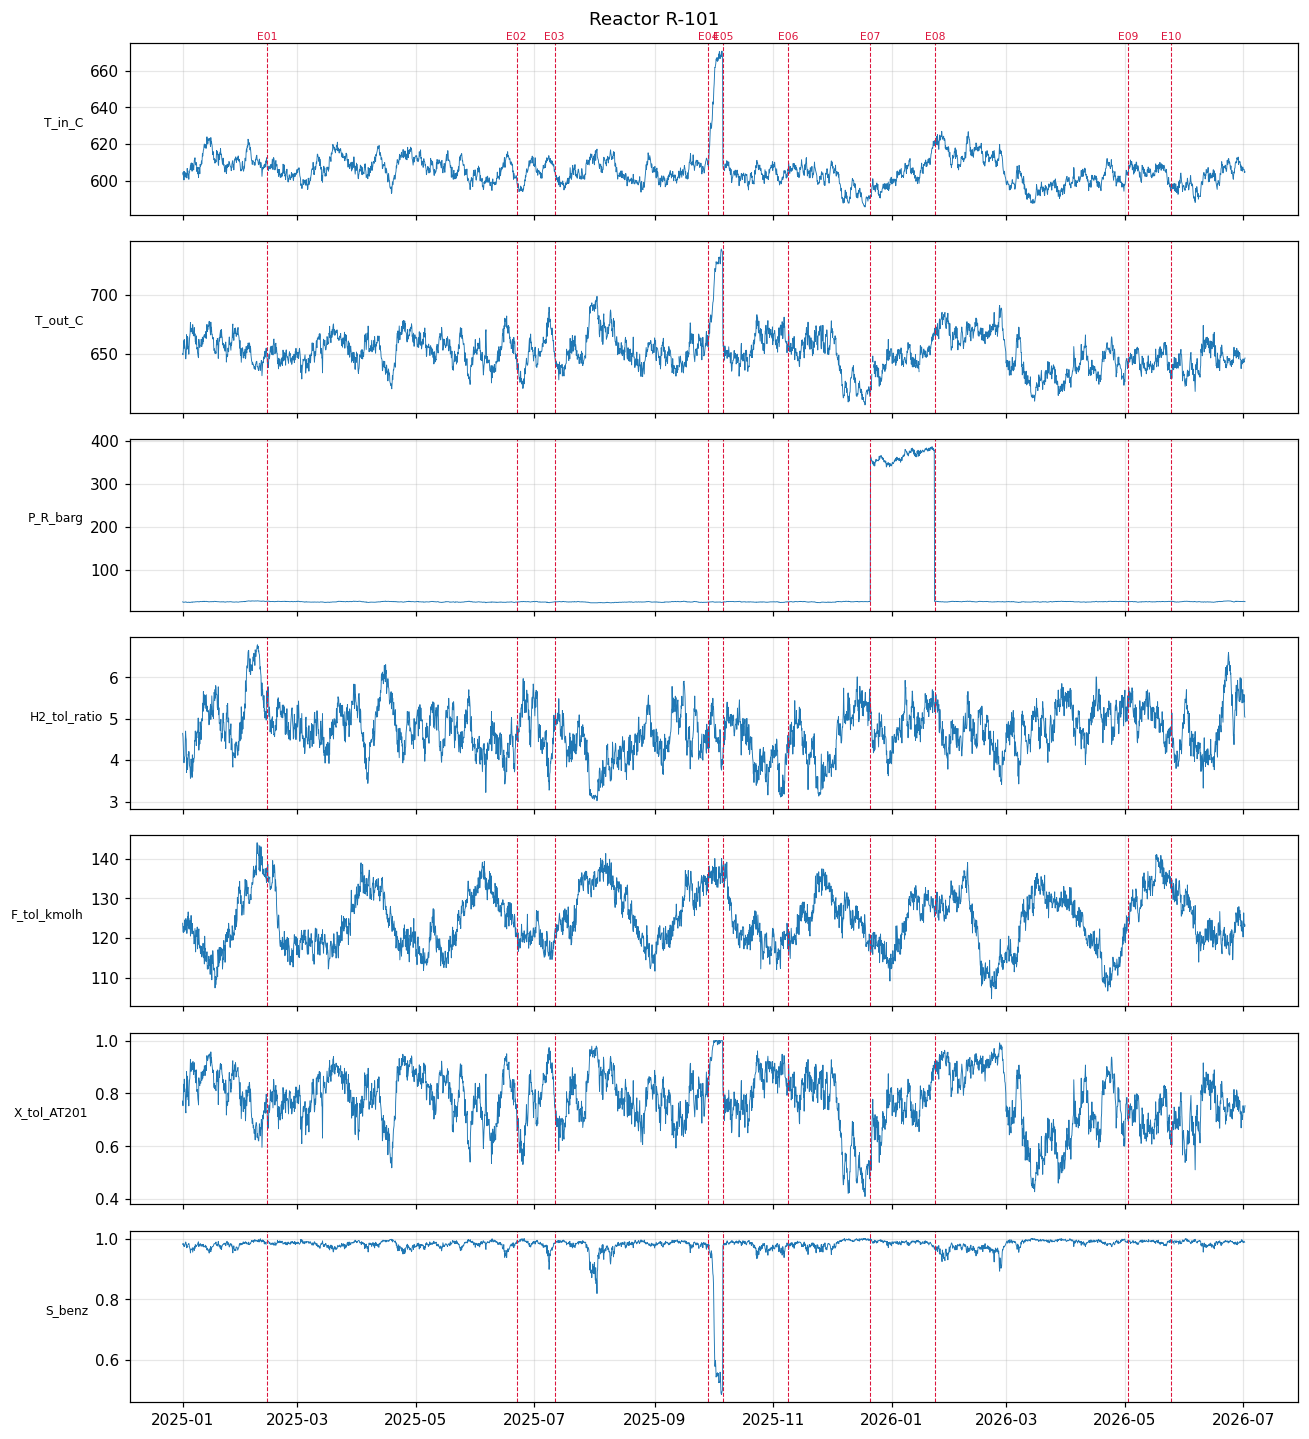

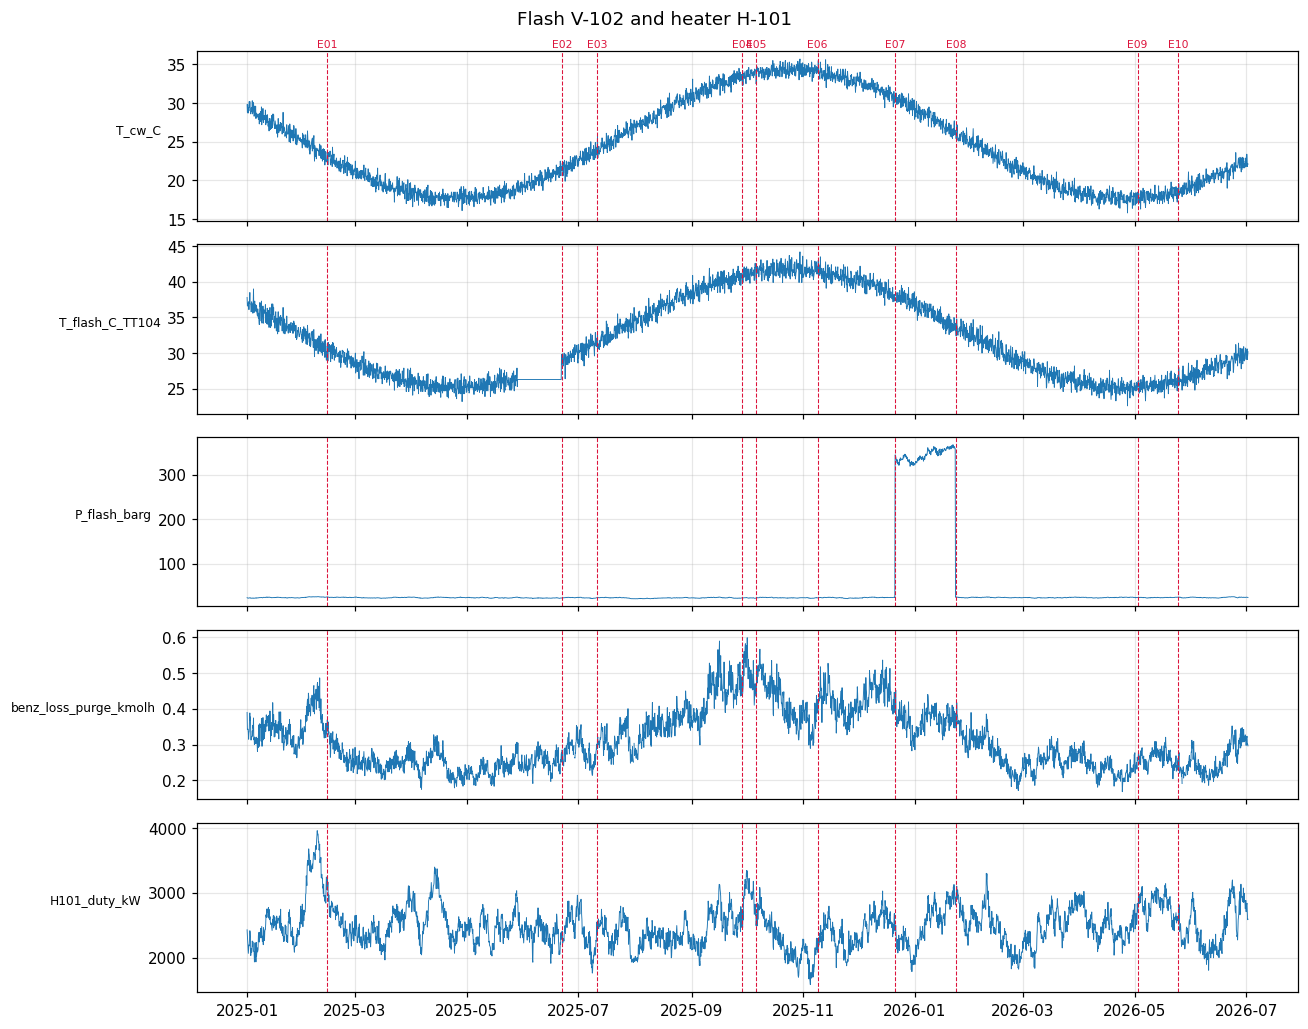

In [ ]:
def ts_plot(df, cols, ev=events, title=""):
    fig, axs = plt.subplots(len(cols), 1, figsize=(12, 1.9 * len(cols)), sharex=True)
    for ax, c in zip(np.atleast_1d(axs), cols):
        ax.plot(df.timestamp, df[c], lw=0.6)
        ax.set_ylabel(c, fontsize=8, rotation=0, ha="right")
        for _, e in ev.iterrows():
            ax.axvline(e.timestamp, color="crimson", ls="--", lw=0.7)
    for _, e in ev.iterrows():
        np.atleast_1d(axs)[0].text(e.timestamp, 1.02, e.event_id, transform=np.atleast_1d(axs)[0].get_xaxis_transform(), fontsize=7, color="crimson", ha="center")
    fig.suptitle(title); plt.tight_layout(); plt.show()

ts_plot(raw, ["T_in_C", "T_out_C", "P_R_barg", "H2_tol_ratio", "F_tol_kmolh", "X_tol_AT201", "S_benz"], title="Reactor R-101")
ts_plot(raw, ["T_cw_C", "T_flash_C_TT104", "P_flash_barg", "benz_loss_purge_kmolh", "H101_duty_kW"], title="Flash V-102 and heater H-101")

### 📘 Audit tools
Three automatic checks help you locate problems. They **suggest** periods; you must confirm them with the plots, the event log and physics.

1. **Frozen-signal check** — a live transmitter always shows small noise. A rolling standard deviation of exactly zero over many samples means the signal is stuck.
2. **Step / unit check** — a sudden jump by a constant factor (with no matching change in other variables) suggests a unit change, not a process change. Ask: *which conversion factor equals the jump?*
3. **Energy-balance consistency check** — for an adiabatic reactor the temperature rise is proportional to the extent of reaction:

$$T_{out}-T_{in}=\frac{\Delta T_{ad}\,X}{1+r}\quad\Rightarrow\quad \theta=\frac{(T_{out}-T_{in})(1+r)}{X}\approx\text{constant}$$

where $r$ is the H₂/toluene ratio. Thermocouples and the analyser are independent instruments. If θ steps **down** while temperatures look normal, the analyser reads **high**.

T_flash_C_TT104    flat from 2025-05-28 20:00:00 to 2025-06-21 16:00:00  (24.0 days)

P_R_barg: samples more than 3x the overall median: 198
first: 2025-12-21 04:00:00  last: 2026-01-23 00:00:00  | typical ratio in that period: 14.63


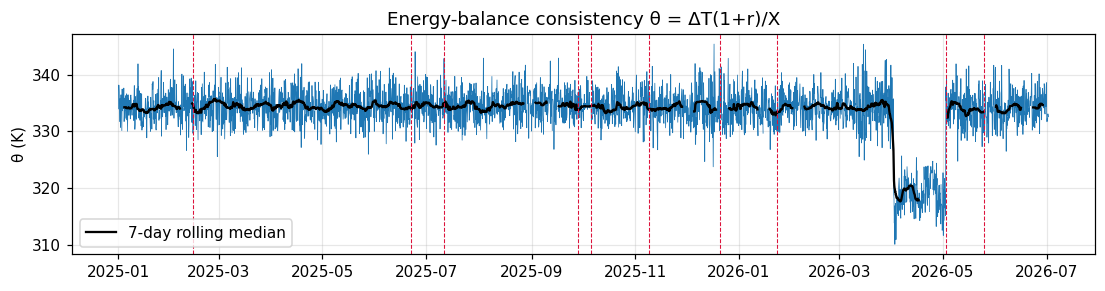

In [ ]:
def frozen_runs(s, window=12):
    rng_ = s.rolling(window).max() - s.rolling(window).min()
    flat = rng_.fillna(1) == 0
    runs, start = [], None
    for i, f in enumerate(flat.values):
        if f and start is None: start = i - window + 1
        if not f and start is not None: runs.append((start, i - 1)); start = None
    if start is not None: runs.append((start, len(s) - 1))
    return runs

for col in ["T_in_C", "T_out_C", "T_flash_C_TT104", "P_R_barg", "P_flash_barg", "X_tol_AT201"]:
    for a, b in frozen_runs(raw[col]):
        print(f"{col:18s} flat from {raw.timestamp[a]} to {raw.timestamp[b]}  ({(b - a + 1) / 6:.1f} days)")

med = raw["P_R_barg"].rolling(60, center=True).median()
jump = raw["P_R_barg"] / raw["P_R_barg"].median()
print("\nP_R_barg: samples more than 3x the overall median:", int((jump > 3).sum()))
print("first:", raw.timestamp[jump > 3].min(), " last:", raw.timestamp[jump > 3].max(),
      " | typical ratio in that period:", round(float(jump[jump > 3].median()), 2))

theta = (raw.T_out_C - raw.T_in_C) * (1 + raw.H2_tol_ratio) / raw.X_tol_AT201
plt.figure(figsize=(12, 2.6)); plt.plot(raw.timestamp, theta, lw=0.5)
plt.plot(raw.timestamp, theta.rolling(42, center=True).median(), "k", lw=1.5, label="7-day rolling median")
for _, e in events.iterrows(): plt.axvline(e.timestamp, color="crimson", ls="--", lw=0.7)
plt.ylabel("θ (K)"); plt.title("Energy-balance consistency θ = ΔT(1+r)/X"); plt.legend(); plt.show()

Candidate intervals — review before choosing cleaning parameters:


,interval,start,end,samples,tags highlighted,evidence,interpretation
0,Likely frozen TT-104,2025-05-28 20:00:00,2025-06-21 16:00:00,144,T_flash_C_TT104,E02: later TT-104 replacement; start inferred ...,Data-inferred sampled boundaries
1,Logged high-temperature trial,2025-09-28 13:00:00,2025-10-06 05:00:00,46,"T_in_C, T_out_C, X_tol_AT201, S_benz, benzene_...","E04 → E05: trial requested, then stopped",Logged interval; highlighted responses may inc...
2,Likely pressure-unit error,2025-12-21 04:00:00,2026-01-23 00:00:00,198,"P_R_barg, P_flash_barg",E07/E08: remapping and unit-table correction; ...,Data-inferred sampled boundaries; psig interpr...
3,Possible positive AT-201 bias,2026-04-02 00:00:00,2026-05-02 12:00:00,184,"X_tol_AT201, theta_K, X_energy_residual",E09: analyser read high; start inferred from e...,Heuristic interval; centred smoothing gives ~1...


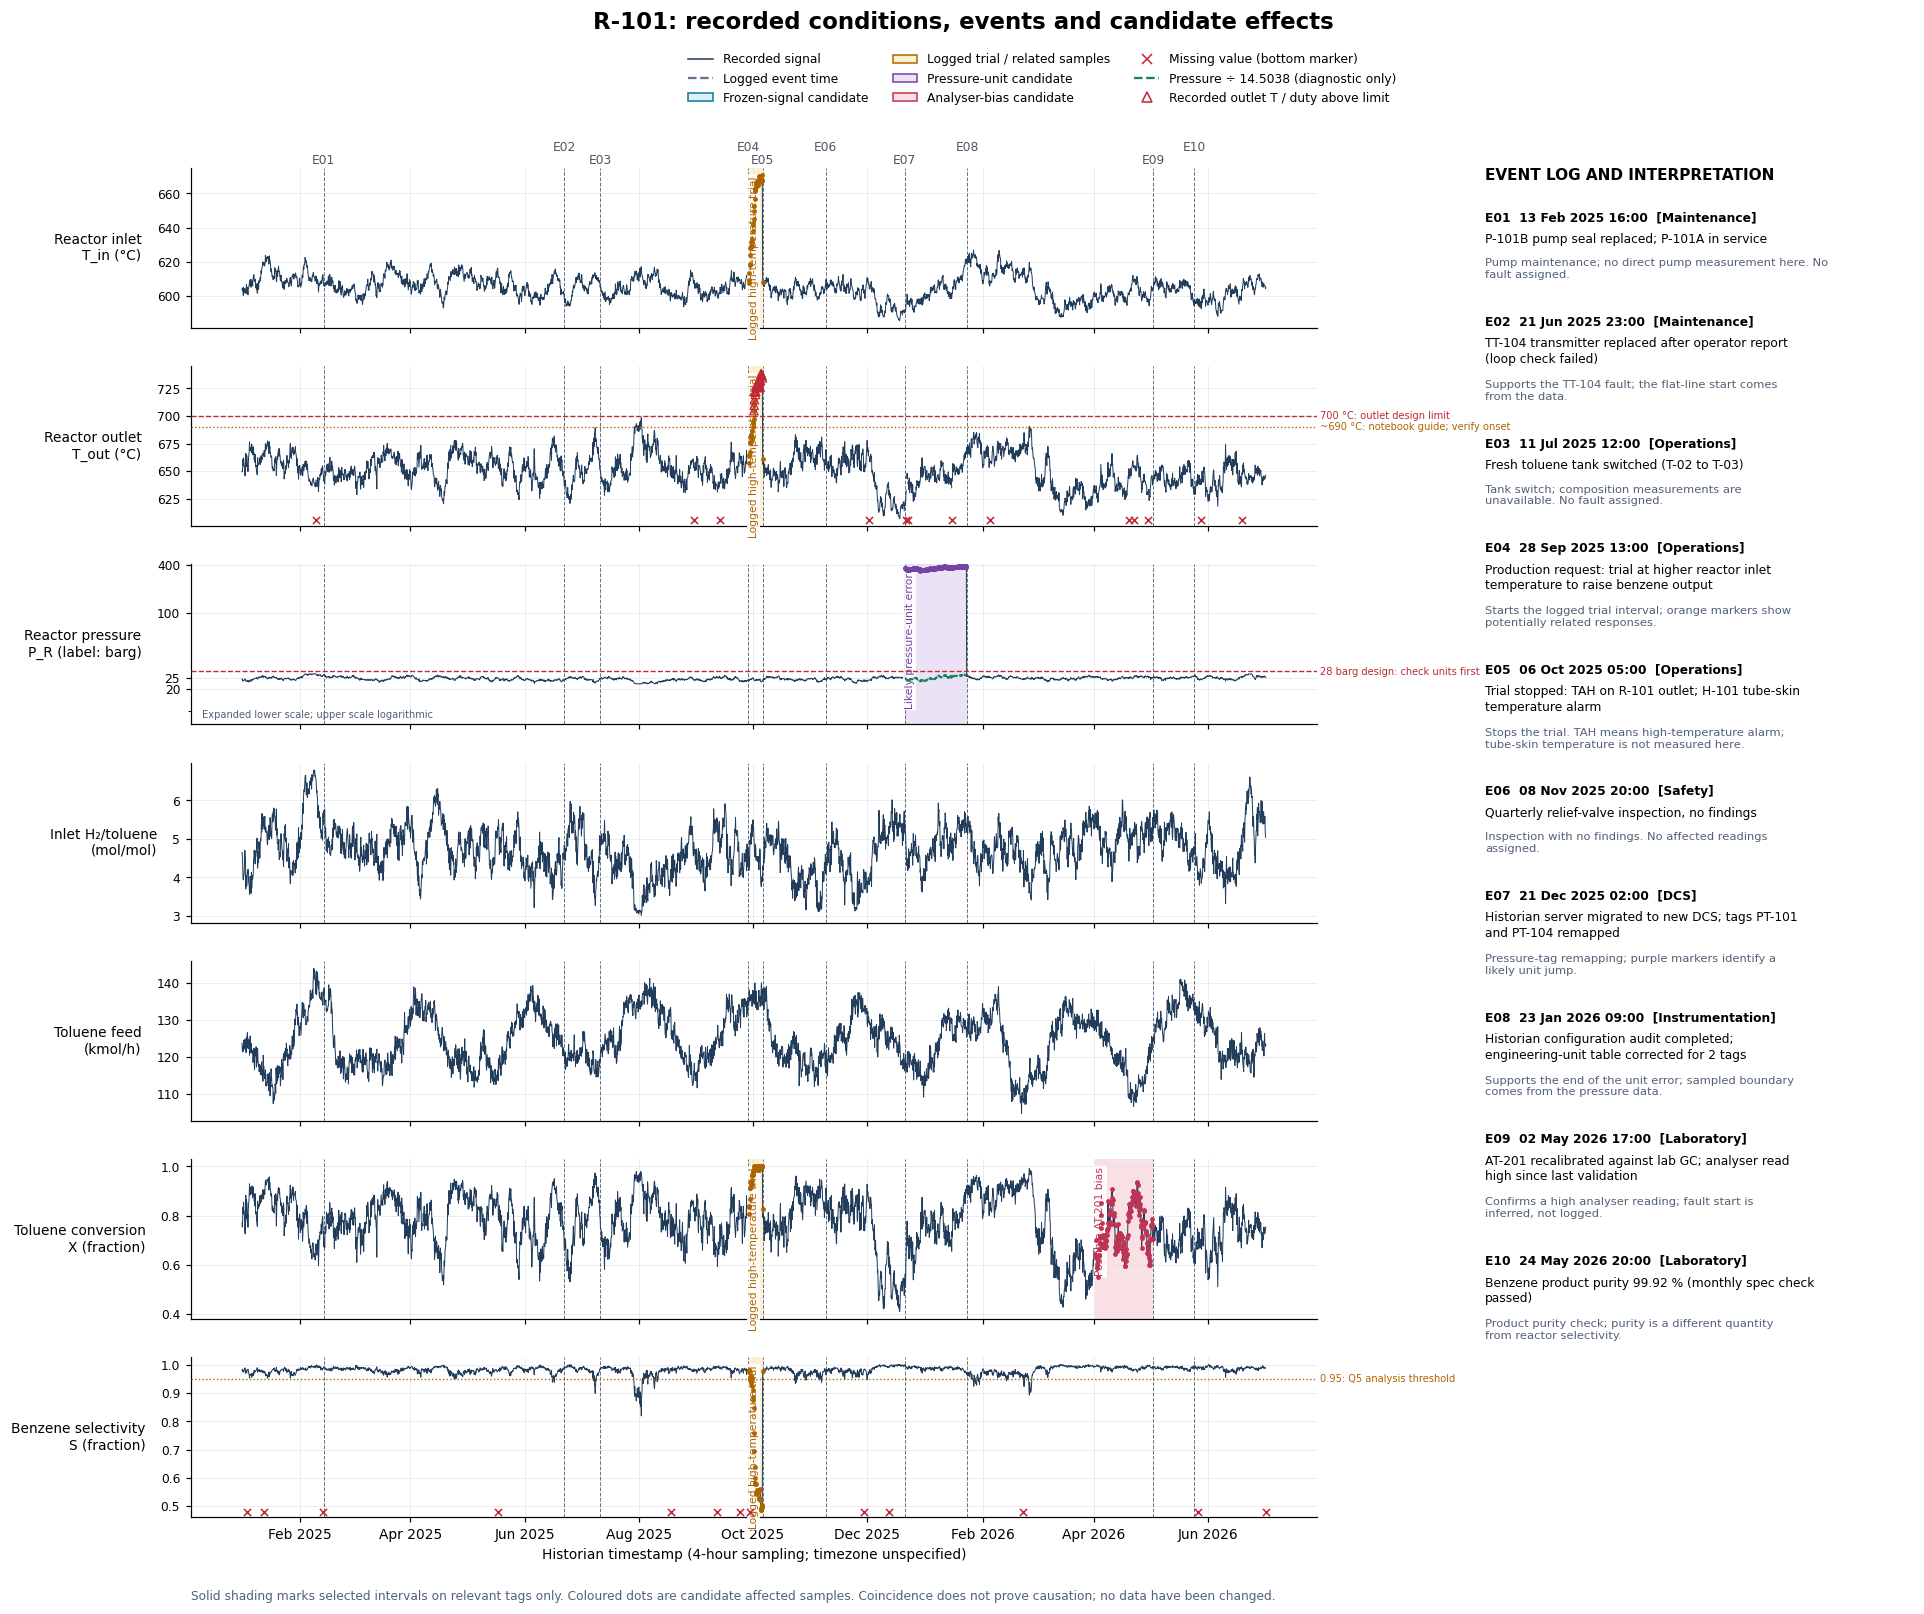

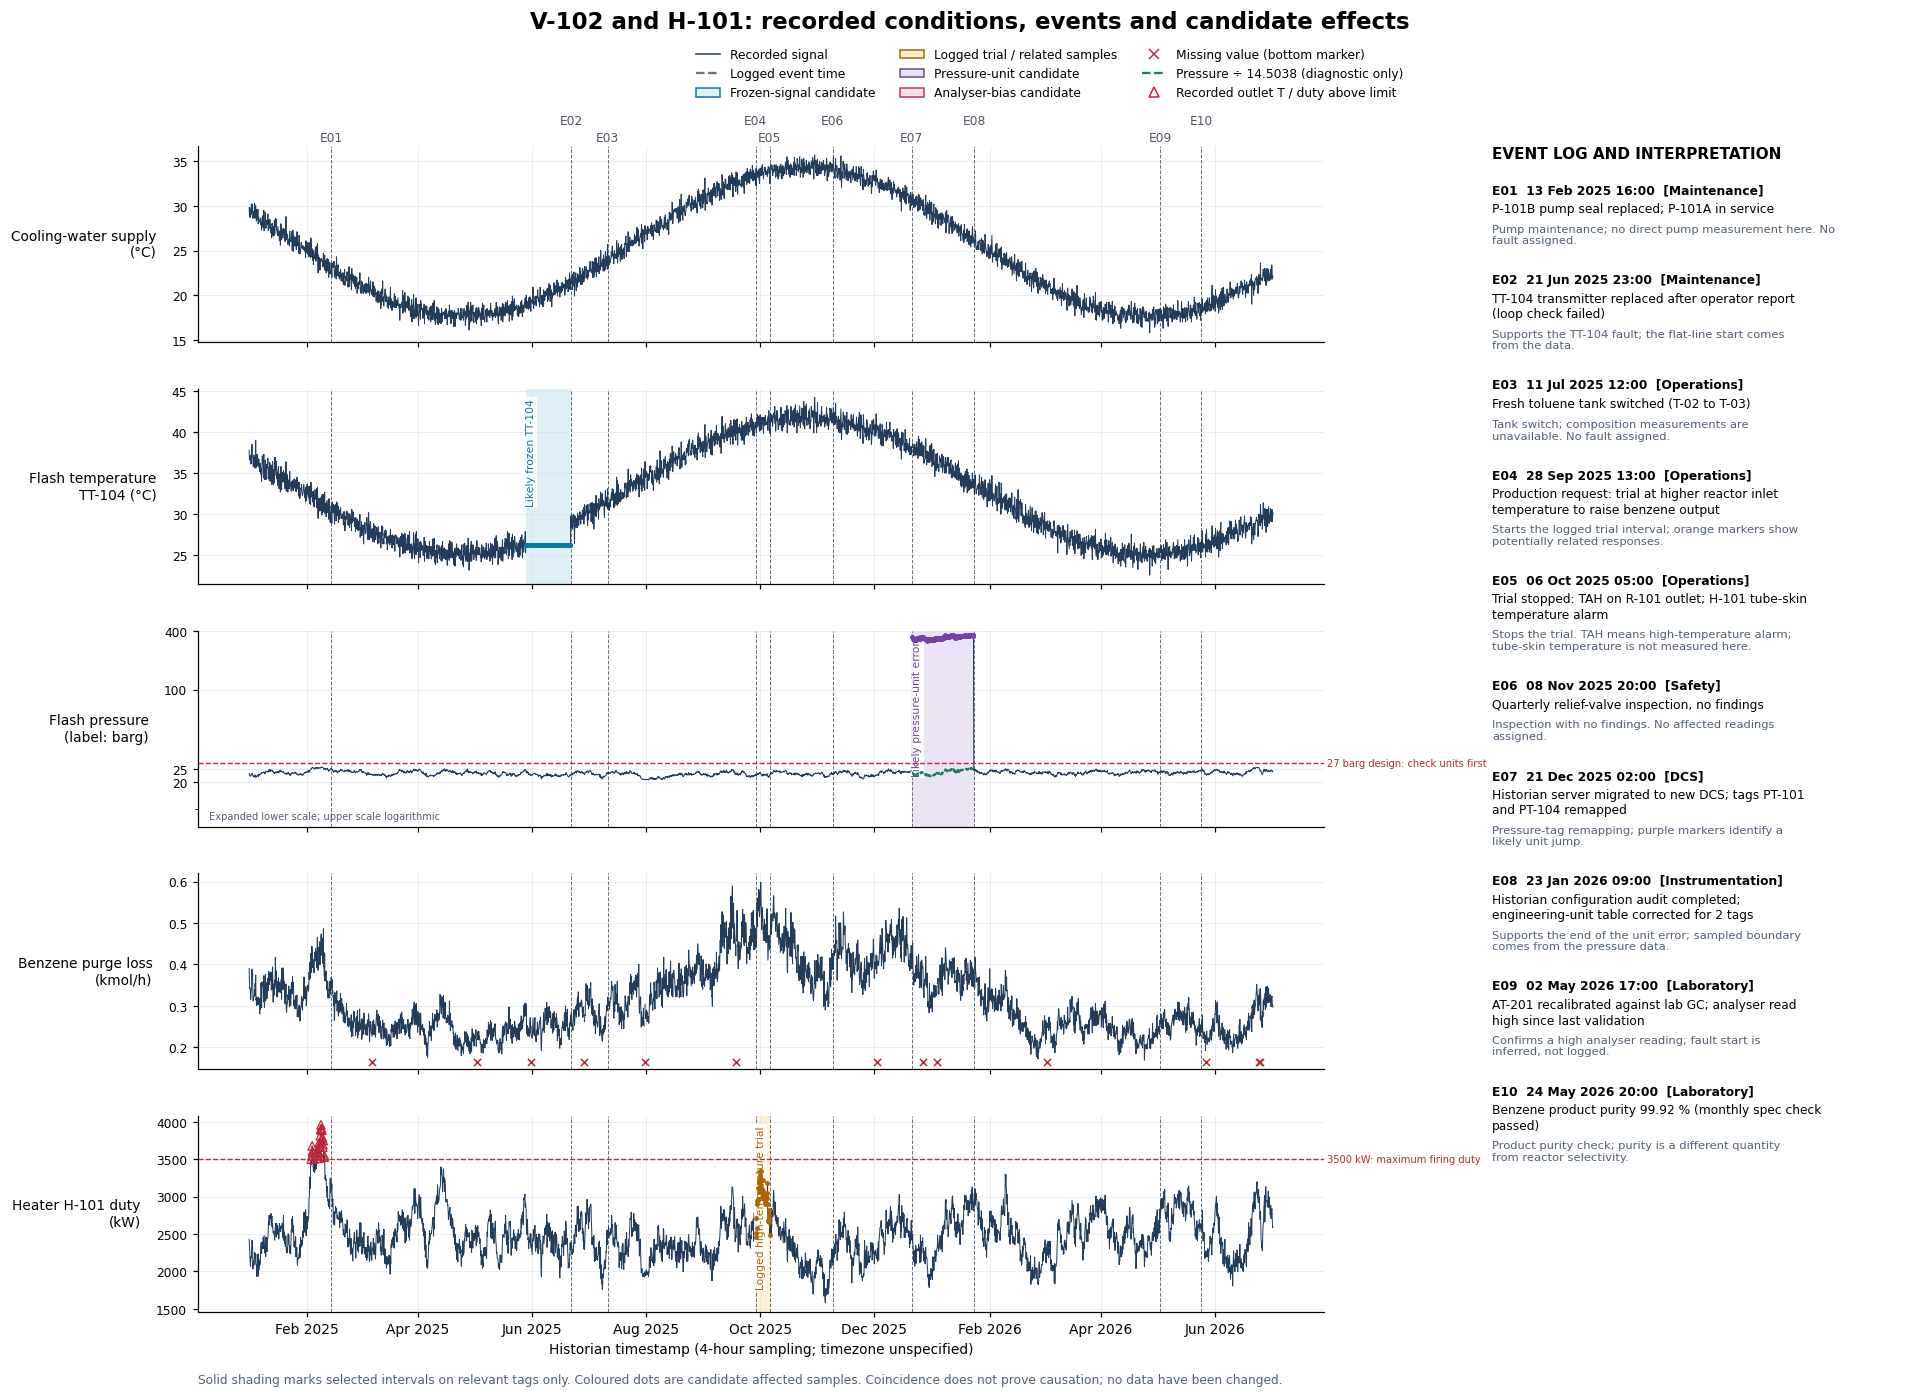

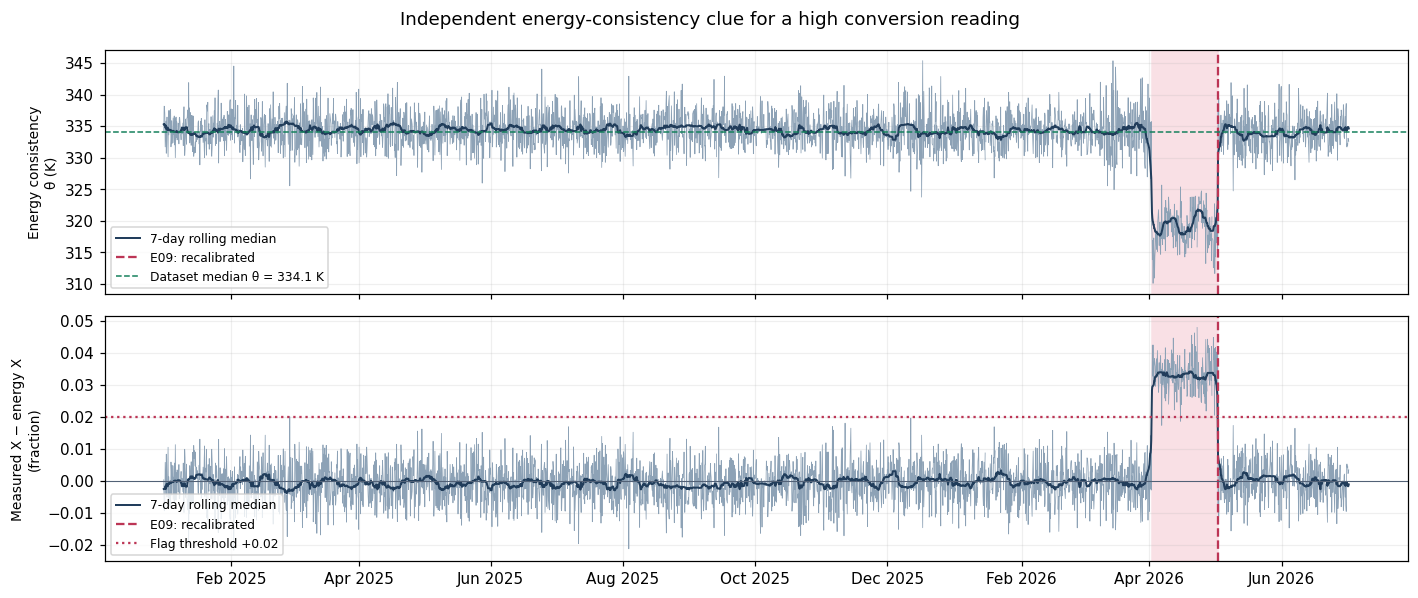

In [ ]:

MIN_FLAT_SAMPLES = 12
PRESSURE_JUMP_FACTOR = 3.0
BIAS_RESIDUAL_THRESHOLD = 0.02
BIAS_ROLLING_SAMPLES = 7
MIN_BIAS_SAMPLES = 12
COLORS = {
    "frozen": ("#deeff5", "#087b9c"),
    "trial": ("#fff0d1", "#ae6400"),
    "units": ("#ece2f6", "#7542a5"),
    "bias": ("#f9e0e5", "#bc3555"),
}
LABELS = {
    "T_in_C": "Reactor inlet\nT_in (°C)",
    "T_out_C": "Reactor outlet\nT_out (°C)",
    "P_R_barg": "Reactor pressure\nP_R (label: barg)",
    "H2_tol_ratio": "Inlet H₂/toluene\n(mol/mol)",
    "F_tol_kmolh": "Toluene feed\n(kmol/h)",
    "X_tol_AT201": "Toluene conversion\nX (fraction)",
    "S_benz": "Benzene selectivity\nS (fraction)",
    "benzene_kmolh": "Benzene formed\n(kmol/h)",
    "T_cw_C": "Cooling-water supply\n(°C)",
    "T_flash_C_TT104": "Flash temperature\nTT-104 (°C)",
    "P_flash_barg": "Flash pressure\n(label: barg)",
    "benz_loss_purge_kmolh": "Benzene purge loss\n(kmol/h)",
    "H101_duty_kW": "Heater H-101 duty\n(kW)",
    "theta_K": "Energy consistency\nθ (K)",
    "X_energy_residual": "Measured X − energy X\n(fraction)",
}


def contiguous_runs(mask):
    """Inclusive integer positions of uninterrupted True samples."""
    pos = np.flatnonzero(np.asarray(mask, dtype=bool))
    if not len(pos):
        return []
    parts = np.split(pos, np.flatnonzero(np.diff(pos) > 1) + 1)
    return [(int(p[0]), int(p[-1])) for p in parts]


def audit_annotations(data, event_log):
    d = data.copy().sort_values("timestamp").reset_index(drop=True)
    d["timestamp"] = pd.to_datetime(d.timestamp)
    ev = event_log.copy()
    ev["timestamp"] = pd.to_datetime(ev.timestamp)
    dates = ev.set_index("event_id").timestamp.to_dict()
    periods = []

    def add(kind, start, end, tags, label, evidence, status):
        periods.append(dict(kind=kind, start=pd.Timestamp(start),
                            end=pd.Timestamp(end), tags=tuple(tags), label=label,
                            evidence=evidence, status=status))


    s = d.T_flash_C_TT104
    groups = s.ne(s.shift()).cumsum()
    for _, g in d.groupby(groups):
        if len(g) >= MIN_FLAT_SAMPLES and g.T_flash_C_TT104.notna().all():
            related = ("E02: later TT-104 replacement; start inferred from flat line"
                       if "E02" in dates and 0 <= (dates["E02"] - g.timestamp.max()).total_seconds() <= 172800
                       else "No nearby repair event; inferred from repeated values")
            add("frozen", g.timestamp.min(), g.timestamp.max(),
                ["T_flash_C_TT104"], "Likely frozen TT-104", related,
                "Data-inferred sampled boundaries")


    p_bad = ((d.P_R_barg > PRESSURE_JUMP_FACTOR * d.P_R_barg.median()) &
             (d.P_flash_barg > PRESSURE_JUMP_FACTOR * d.P_flash_barg.median()))
    if "E07" in dates and "E08" in dates:
        p_bad &= d.timestamp.between(dates["E07"], dates["E08"])
    for a, b in contiguous_runs(p_bad):
        add("units", d.timestamp.iloc[a], d.timestamp.iloc[b],
            ["P_R_barg", "P_flash_barg"], "Likely pressure-unit error",
            "E07/E08: remapping and unit-table correction; simultaneous large jumps",
            "Data-inferred sampled boundaries; psig interpretation to verify")


    if "E04" in dates and "E05" in dates:
        add("trial", dates["E04"], dates["E05"],
            ["T_in_C", "T_out_C", "X_tol_AT201", "S_benz",
             "benzene_kmolh", "H101_duty_kW", "theta_K", "X_energy_residual"],
            "Logged high-temperature trial", "E04 → E05: trial requested, then stopped",
            "Logged interval; highlighted responses may include other effects")


    valid_x = d.X_tol_AT201.where(d.X_tol_AT201 > 0)
    d["theta_K"] = (d.T_out_C - d.T_in_C) * (1 + d.H2_tol_ratio) / valid_x
    theta_ref = d.theta_K.replace([np.inf, -np.inf], np.nan).median()
    d["X_energy_residual"] = (d.X_tol_AT201 -
        (d.T_out_C - d.T_in_C) * (1 + d.H2_tol_ratio) / theta_ref)
    smooth = d.X_energy_residual.rolling(
        BIAS_ROLLING_SAMPLES, center=True,
        min_periods=max(1, (BIAS_ROLLING_SAMPLES + 1)//2)).median()
    bias = smooth.gt(BIAS_RESIDUAL_THRESHOLD)
    if "E09" in dates:
        bias &= d.timestamp < dates["E09"]
    for a, b in contiguous_runs(bias):
        if b - a + 1 >= MIN_BIAS_SAMPLES:
            add("bias", d.timestamp.iloc[a], d.timestamp.iloc[b],
                ["X_tol_AT201", "theta_K", "X_energy_residual"],
                "Possible positive AT-201 bias",
                "E09: analyser read high; start inferred from energy consistency",
                "Heuristic interval; centred smoothing gives ~12 h boundary uncertainty")

    records = []
    for p in sorted(periods, key=lambda p: p["start"]):
        in_period = d.timestamp.between(p["start"], p["end"])
        records.append({"interval": p["label"], "start": p["start"], "end": p["end"],
                        "samples": int(in_period.sum()),
                        "tags highlighted": ", ".join(p["tags"]),
                        "evidence": p["evidence"], "interpretation": p["status"]})
    return d, periods, pd.DataFrame(records), float(theta_ref)


def ts_plot(df, cols, ev=None, title="", periods=None):
    """Same call pattern as the original function, with an event-description panel."""
    if ev is None:
        ev = events
    if periods is None:
        _, periods, _, _ = audit_annotations(df, ev)
    d = df.copy().sort_values("timestamp")
    d["timestamp"] = pd.to_datetime(d.timestamp)
    ev = ev.copy().sort_values("timestamp")
    ev["timestamp"] = pd.to_datetime(ev.timestamp)
    fig = plt.figure(figsize=(18, max(13, 2.15 * len(cols))))
    gs = fig.add_gridspec(len(cols), 2, width_ratios=[3.45, 1.6],
                          left=.11, right=.98, bottom=.075, top=.89,
                          hspace=.24, wspace=.09)
    axes = []
    limits = {
        "T_out_C": [(690, "#ae6400", "~690 °C: notebook guide; verify onset", ":"),
                    (700, "#bd2935", "700 °C: outlet design limit", "--")],
        "P_R_barg": [(28, "#bd2935", "28 barg design: check units first", "--")],
        "P_flash_barg": [(27, "#bd2935", "27 barg design: check units first", "--")],
        "H101_duty_kW": [(3500, "#bd2935", "3500 kW: maximum firing duty", "--")],
        "S_benz": [(.95, "#ae6400", "0.95: Q5 analysis threshold", ":")],
        "X_energy_residual": [(BIAS_RESIDUAL_THRESHOLD, "#bc3555",
                               "+0.02: diagnostic threshold", ":")],
    }
    dt = d.timestamp.diff().median()
    half_sample = dt / 2 if pd.notna(dt) else pd.Timedelta(hours=2)
    for i, c in enumerate(cols):
        ax = fig.add_subplot(gs[i, 0], sharex=axes[0] if axes else None)
        axes.append(ax)
        ax.set_facecolor("#ffffff")
        ax.set_axisbelow(True)
        ax.grid(True, color="#d7dfe7", lw=.5, alpha=.65)
        for p in periods:
            if c not in p["tags"]:
                continue
            pale, dark = COLORS[p["kind"]]
            # Solid pale colour, fully opaque; the data line sits above it.
            sampled = p["kind"] != "trial"
            ax.axvspan(p["start"] - (half_sample if sampled else pd.Timedelta(0)),
                       p["end"] + (half_sample if sampled else pd.Timedelta(0)),
                       facecolor=pale, alpha=1.0, zorder=0)
            mask = d.timestamp.between(p["start"], p["end"]) & d[c].notna()
            ax.scatter(d.loc[mask, "timestamp"], d.loc[mask, c],
                       color=dark, s=10, zorder=4, linewidths=0)
            if mask.any():
                ax.text(d.loc[mask, "timestamp"].iloc[0], .95,
                        p["label"].replace("Possible positive ", "Possible "),
                        transform=ax.get_xaxis_transform(), fontsize=7,
                        color=dark, va="top", rotation=90,
                        bbox=dict(facecolor="white", alpha=.9, edgecolor="none", pad=1))
                if p["kind"] == "units":
                    ax.plot(d.loc[mask, "timestamp"], d.loc[mask, c] / 14.5038,
                            color="#16815d", lw=1.2, ls="--", zorder=5)
        ax.plot(d.timestamp, d[c], color="#213d5b", lw=.65, zorder=2)
        for _, e in ev.iterrows():
            ax.axvline(e.timestamp, color="#677384", ls="--", lw=.65, zorder=1)
        for value, color, label, style in limits.get(c, []):
            ax.axhline(value, color=color, ls=style, lw=.9, zorder=3)
            ax.text(1.003, value, label, transform=ax.get_yaxis_transform(),
                    fontsize=6.5, color=color, va="center", ha="left",
                    bbox=dict(facecolor="white", edgecolor="none", pad=.3))

        direct_limit = {"T_out_C": 700, "H101_duty_kW": 3500}.get(c)
        if direct_limit is not None:
            above = d[c] > direct_limit
            ax.scatter(d.loc[above, "timestamp"], d.loc[above, c],
                       marker="^", facecolors="none", edgecolors="#c02638",
                       s=30, lw=.8, zorder=6)
        missing = d[c].isna()
        if missing.any():
            ax.scatter(d.loc[missing, "timestamp"], np.full(missing.sum(), .035),
                       transform=ax.get_xaxis_transform(), color="#c02638",
                       marker="x", s=22, lw=1, zorder=5)
        if c.startswith("P_") and d[c].max() > 3 * d[c].median():
            # A linear scale would hide normal 22–26 barg variation below 380.
            ax.set_yscale("symlog", linthresh=40, linscale=1.0)
            ax.set_yticks([20, 25, 100, 400])
            ax.set_yticklabels(["20", "25", "100", "400"])
            ax.text(.01, .04, "Expanded lower scale; upper scale logarithmic",
                    transform=ax.transAxes, fontsize=6.5, color="#526176")
        ax.set_ylabel(LABELS.get(c, c), fontsize=9, rotation=0,
                      ha="right", va="center", labelpad=10)
        ax.tick_params(axis="y", labelsize=8)
        ax.tick_params(axis="x", labelbottom=i == len(cols) - 1, labelsize=9)
        ax.spines[["top", "right"]].set_visible(False)
    for j, (_, e) in enumerate(ev.iterrows()):
        axes[0].text(e.timestamp, 1.025 + .085 * (j % 2), e.event_id,
                     transform=axes[0].get_xaxis_transform(), fontsize=8,
                     ha="center", color="#4b5563")
    axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    axes[-1].set_xlabel("Historian timestamp (4-hour sampling; timezone unspecified)", fontsize=9)

    side = fig.add_subplot(gs[:, 1])
    side.axis("off")
    notes = {
        "E01": "Pump maintenance; no direct pump measurement here. No fault assigned.",
        "E02": "Supports the TT-104 fault; the flat-line start comes from the data.",
        "E03": "Tank switch; composition measurements are unavailable. No fault assigned.",
        "E04": "Starts the logged trial interval; orange markers show potentially related responses.",
        "E05": "Stops the trial. TAH means high-temperature alarm; tube-skin temperature is not measured here.",
        "E06": "Inspection with no findings. No affected readings assigned.",
        "E07": "Pressure-tag remapping; purple markers identify a likely unit jump.",
        "E08": "Supports the end of the unit error; sampled boundary comes from the pressure data.",
        "E09": "Confirms a high analyser reading; fault start is inferred, not logged.",
        "E10": "Product purity check; purity is a different quantity from reactor selectivity.",
    }
    side.text(.18, 1.0, "EVENT LOG AND INTERPRETATION", fontsize=10,
              weight="bold", va="top", transform=side.transAxes)
    visible = ev[ev.timestamp.between(d.timestamp.min(), d.timestamp.max())]
    y = .968
    for _, e in visible.iterrows():
        heading = f"{e.event_id}  {e.timestamp:%d %b %Y %H:%M}  [{e.category}]"
        message = textwrap.fill(str(e.entry), width=51)
        interpretation = textwrap.fill(notes.get(e.event_id, "Context only; inspect the data before assigning effects."), width=53)
        side.text(.18, y, heading, fontsize=8, weight="bold", va="top")
        side.text(.18, y-.016, message, fontsize=8, va="top", linespacing=1.25)
        ny = y - .016 - .0128 * (message.count("\n") + 1) - .006
        side.text(.18, ny, interpretation, fontsize=7.5, color="#526176",
                  va="top", linespacing=1.2)
        y = ny - .0128 * (interpretation.count("\n") + 1) - .017
    fig.suptitle(title, fontsize=15, weight="bold", y=.985)
    handles = [Line2D([], [], color="#213d5b", lw=1, label="Recorded signal"),
               Line2D([], [], color="#677384", ls="--", label="Logged event time")]
    handles += [Patch(facecolor=COLORS[k][0], edgecolor=COLORS[k][1], label=lab)
                for k, lab in [("frozen", "Frozen-signal candidate"),
                               ("trial", "Logged trial / related samples"),
                               ("units", "Pressure-unit candidate"),
                               ("bias", "Analyser-bias candidate")]]
    handles += [Line2D([], [], color="#c02638", marker="x", ls="none", label="Missing value (bottom marker)"),
                Line2D([], [], color="#16815d", ls="--", label="Pressure ÷ 14.5038 (diagnostic only)")]
    handles += [Line2D([], [], color="#c02638", marker="^", markerfacecolor="none",
                       ls="none", label="Recorded outlet T / duty above limit")]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.54, .966),
               ncol=3, fontsize=8, frameon=False)
    fig.text(.11, .025,
             "Solid shading marks selected intervals on relevant tags only. Coloured dots are candidate affected samples. "
             "Coincidence does not prove causation; no data have been changed.", fontsize=8, color="#526176")
    plt.show()
    return fig


if "raw" not in globals() or "events" not in globals():
    script_dir = Path(globals().get("__file__", Path.cwd()/"plot_cell.py")).resolve().parent
    source = next((p for p in [Path.cwd(), Path.cwd()/"upload", script_dir]
                   if (p/"hda_ops_230144.csv").exists() and (p/"hda_events_230144.csv").exists()), None)
    if source is None:
        raise FileNotFoundError("Run the notebook setup first, or place both student-230144 CSV files beside this script.")
    raw = pd.read_csv(source/"hda_ops_230144.csv", parse_dates=["timestamp"])
    events = pd.read_csv(source/"hda_events_230144.csv", parse_dates=["timestamp"])

audit_view, audit_periods, audit_table, theta_reference = audit_annotations(raw, events)
print("Candidate intervals — review before choosing cleaning parameters:")
try:
    from IPython.display import display
    display(audit_table)
except ImportError:
    print(audit_table.to_string(index=False))

fig_reactor = ts_plot(raw, ["T_in_C", "T_out_C", "P_R_barg", "H2_tol_ratio",
                            "F_tol_kmolh", "X_tol_AT201", "S_benz"],
                       title="R-101: recorded conditions, events and candidate effects", periods=audit_periods)
fig_flash = ts_plot(raw, ["T_cw_C", "T_flash_C_TT104", "P_flash_barg",
                          "benz_loss_purge_kmolh", "H101_duty_kW"],
                     title="V-102 and H-101: recorded conditions, events and candidate effects", periods=audit_periods)

fig_energy, energy_axes = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
for ax, c in zip(energy_axes, ["theta_K", "X_energy_residual"]):
    ax.plot(audit_view.timestamp, audit_view[c], lw=.5, color="#8da2b6")
    ax.plot(audit_view.timestamp, audit_view[c].rolling(42, center=True, min_periods=21).median(),
            color="#213d5b", lw=1.3, label="7-day rolling median")
    for p in audit_periods:
        if p["kind"] == "bias":
            ax.axvspan(p["start"], p["end"], color=COLORS["bias"][0], alpha=1, zorder=0)
    for _, e in events.iterrows():
        if e.event_id == "E09":
            ax.axvline(pd.Timestamp(e.timestamp), ls="--", color="#bc3555", label="E09: recalibrated")
    ax.set_ylabel(LABELS[c], fontsize=9)
    ax.grid(True, alpha=.2)
energy_axes[0].axhline(theta_reference, color="#16815d", ls="--", lw=1,
                      label=f"Dataset median θ = {theta_reference:.1f} K")
energy_axes[1].axhline(BIAS_RESIDUAL_THRESHOLD, color="#bc3555", ls=":", label="Flag threshold +0.02")
energy_axes[1].axhline(0, color="#526176", lw=.7)
for ax in energy_axes:
    ax.legend(loc="lower left", fontsize=8)
energy_axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
energy_axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig_energy.suptitle("Independent energy-consistency clue for a high conversion reading", fontsize=12)
fig_energy.tight_layout()
plt.show()


### ❓ Q1 · Data audit (graded, 15 %)
Using **your** plots, the audit tools and the event log, list **every** data problem in your dataset.
For each one give: (a) affected tag(s); (b) first and last bad timestamp; (c) the event ID(s) that support it — or state that the log does not give the start/end and how you found it from the data; (d) one physical argument showing the data, not the process, changed (e.g. which other variable *should* have moved but did not).

*Hint:* at least one problem has **no** event-log entry for its start. One event-log entry is a real process change, not a data problem — treat it differently.

✏️ **Your answer:**

| Problem | Details |
|---|---|
| Frozen TT-104 | 28/05/2025 20:00 →<br>21/06/2025 16:00<br>144 readings stayed at 26.3 °C<br>while cooling water changed.<br>E02: failed check and replacement.<br>Start found from the flat line. |
| Wrong pressure units<br>PT-101, PT-104 | 21/12/2025 04:00 →<br>23/01/2026 00:00<br>Both pressures suddenly jumped.<br>E07–E08: tags remapped, units fixed.<br>Dividing by 14.5038 restores<br>normal readings below both limits. |
| AT-201 reading high | 02/04/2026 00:00 →<br>02/05/2026 12:00<br>Conversion was too high for<br>the measured temperature rise.<br>E09 confirms the high reading.<br>Start found from the energy check. |
| Missing T_out_C | 09/02/2025 16:00 →<br>19/06/2026 08:00<br>13 blanks; intermittent.<br>Found using isna().<br>No logged cause; blanks are unknown. |
| Missing S_benz | 03/01/2025 20:00 →<br>02/07/2026 00:00<br>13 blanks; intermittent.<br>Found using isna().<br>No logged cause; blanks are unknown. |
| Missing purge loss<br>benz_loss_purge_kmolh | 07/03/2025 12:00 →<br>25/06/2026 00:00<br>13 blanks; intermittent.<br>Found using isna().<br>No logged cause; blanks are unknown. |
| Outlet above 700 °C<br>T_out_C | 01/10/2025 12:00 →<br>06/10/2025 00:00<br>28 readings; peak 738.5 °C.<br>E04–E05: temperature trial.<br>Other readings changed together.<br>Real process change. |
| Duty above 3,500 kW<br>H101_duty_kW | 03/02/2025 04:00 →<br>10/02/2025 08:00<br>30 readings; intermittent.<br>Peak 3,962 kW; gas flow was high (especially H$_2$).<br>No logged cause.<br>Limit exceedance needs checking. |
| Possible conversion cap<br>AT-201 | 01/10/2025 12:00 →<br>05/10/2025 20:00<br>14 readings equal 1.0000.<br>During the E04–E05 trial.<br>Could be rounding or capping at maximum conversion, that is 1.0.<br>A fault is unconfirmed. |

## Step 3 · Clean the data
📘 Enter the periods you found in Q1. Use the format `"YYYY-MM-DD HH:MM"`.
* **Unit error:** convert back with the correct factor (1 bar = 14.5038 psi) — do not delete data you can repair.
* **Frozen sensor:** set the stuck values to `NaN` (the true value is unknown).
* **Analyser offset:** either drop the period or subtract the offset you estimate. Justify your choice in Q2.

If a parameter stays `None`, that correction is **not applied** — and the later results will show it.

In [ ]:
# Pressure recorded in the wrong unit
PSIG_START = "2025-12-21 04:00"
PSIG_END   = "2026-01-23 00:00"

# Frozen flash-temperature signal
FROZEN_START = "2025-05-28 20:00"
FROZEN_END   = "2025-06-21 16:00"

# Conversion analyser reading too high
BIAS_START = "2026-04-02 00:00"
BIAS_END   = "2026-05-02 12:00"

Pressure converted from psig to barg: 198 rows.
Frozen TT-104 values set to NaN: 144 rows.
Drop case: 184 bias-period rows removed.
Corrected case: 184 conversion readings reduced by 0.034.

Both datasets are available in datasets:
     case  rows  bias rows kept  offset subtracted
     drop  3099               0              0.000
corrected  3283             184              0.034


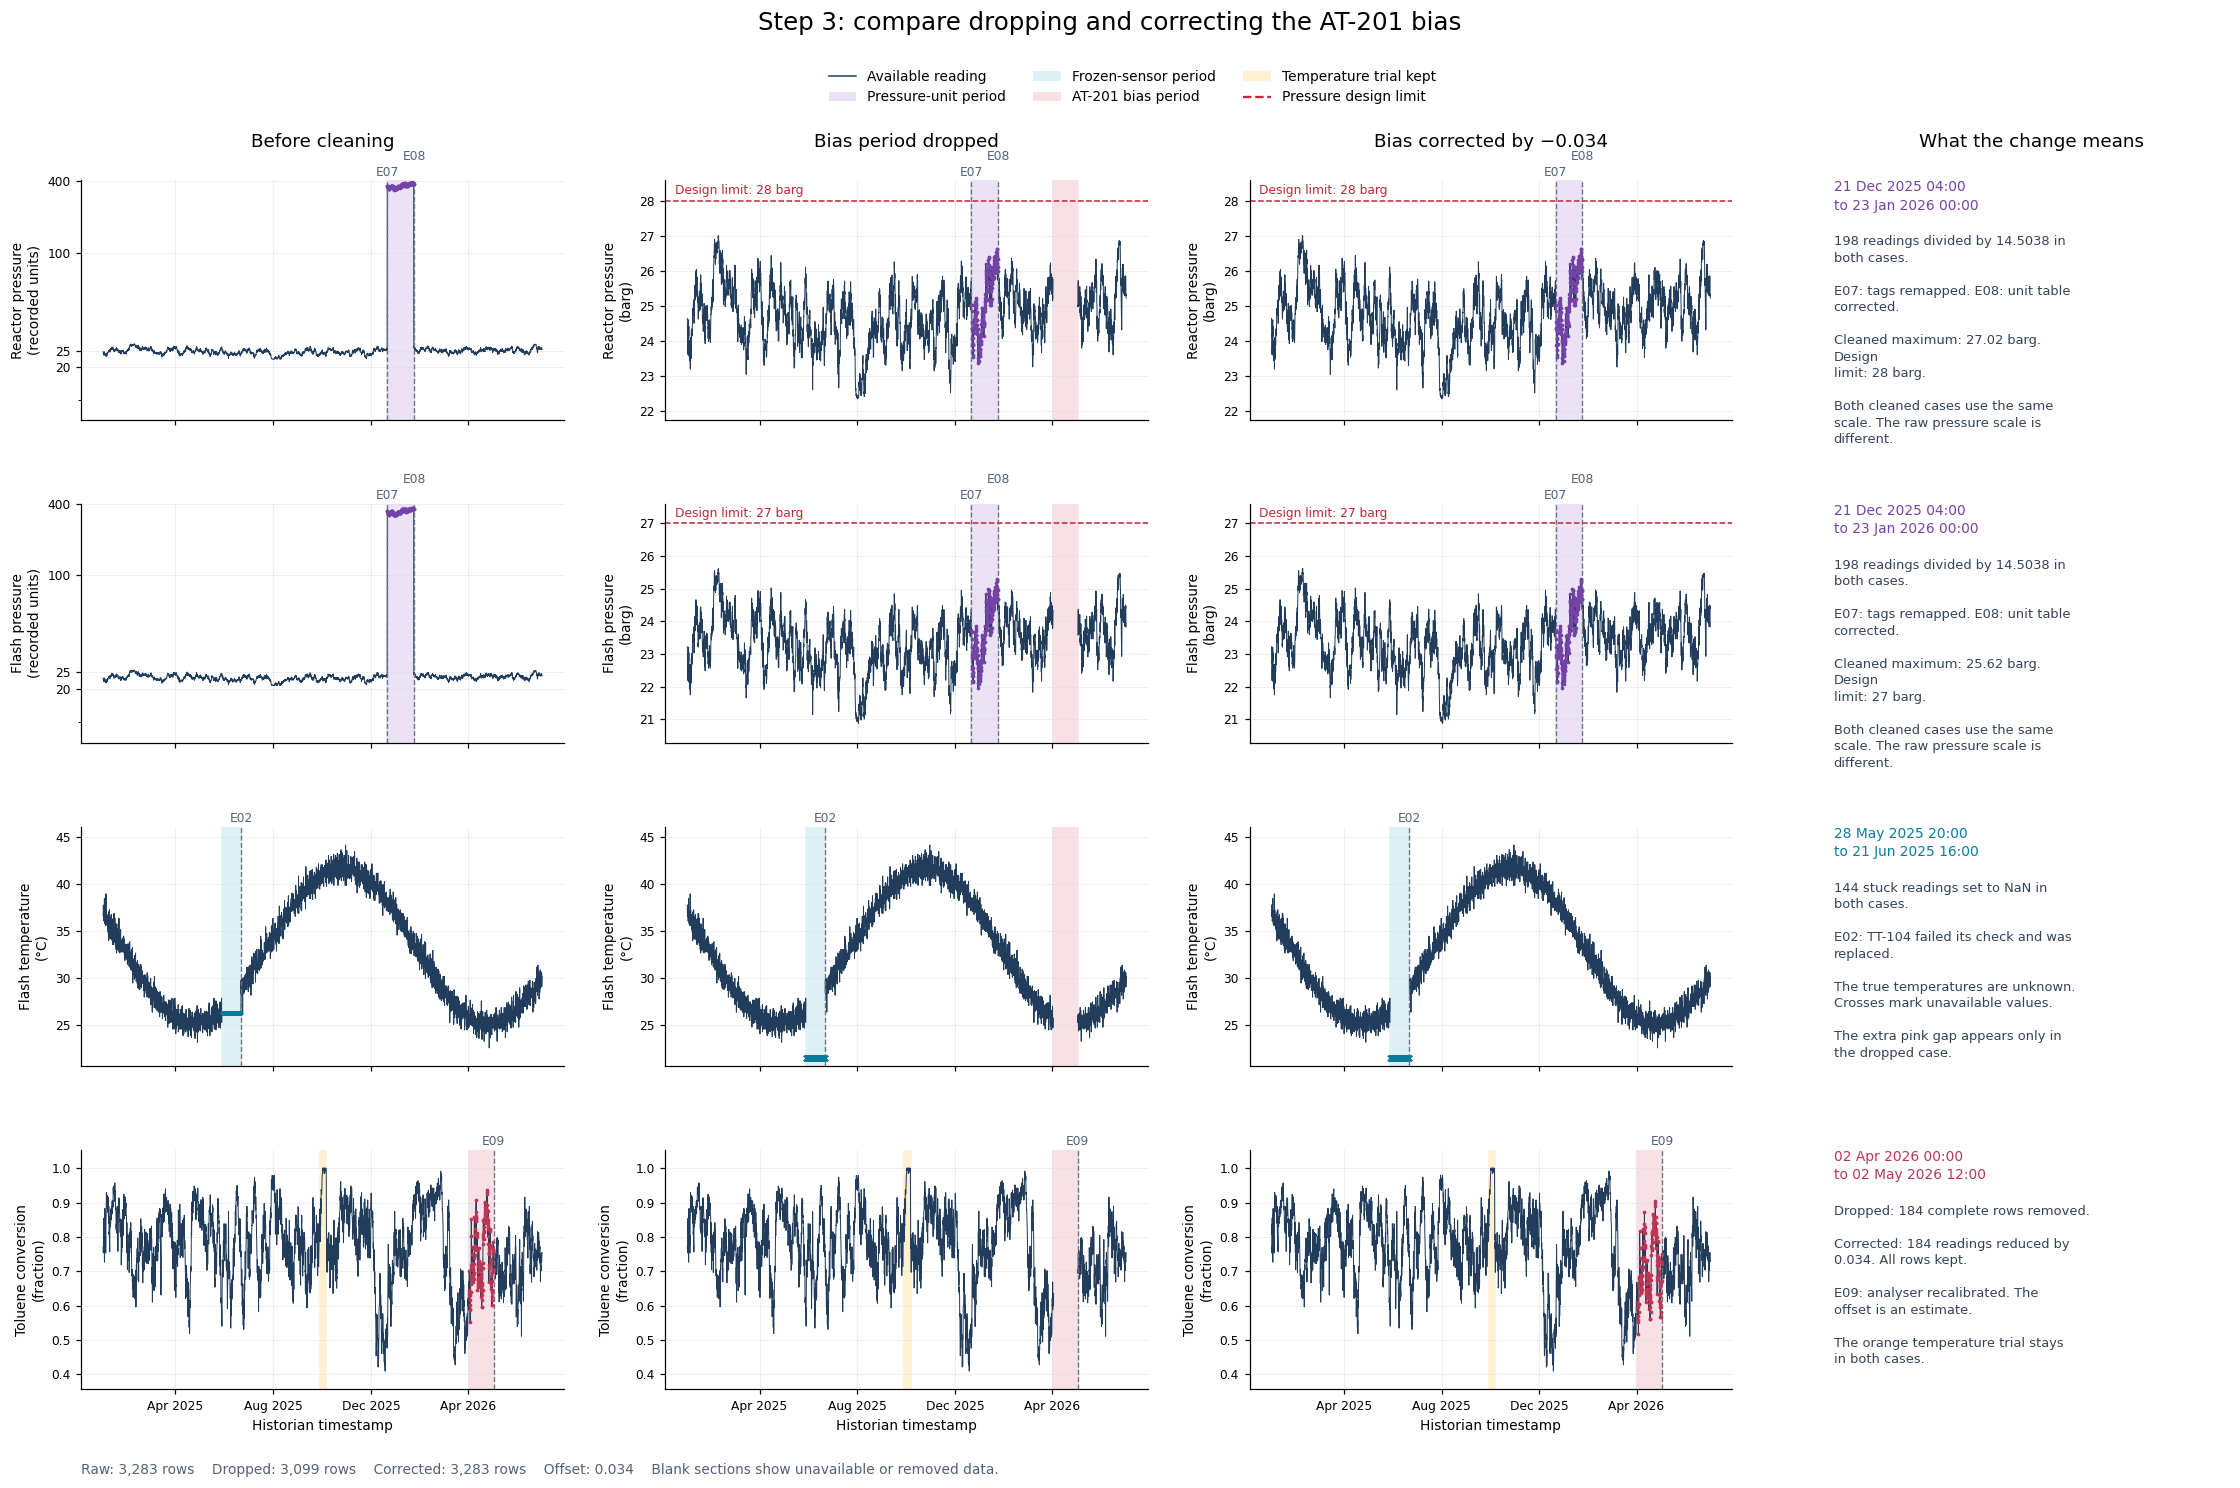

In [ ]:
source = raw.copy().sort_values("timestamp").reset_index(drop=True)
source["timestamp"] = pd.to_datetime(source["timestamp"])


def between(a, b):
    if a is None and b is None:
        return pd.Series(False, index=source.index)
    if a is None or b is None:
        raise ValueError("Enter both the start and end of each selected period.")
    if pd.Timestamp(a) > pd.Timestamp(b):
        raise ValueError("A period's start must be before its end.")
    return source.timestamp.between(pd.Timestamp(a), pd.Timestamp(b))


m_pressure = between(PSIG_START, PSIG_END)
m_frozen = between(FROZEN_START, FROZEN_END)
m_bias = between(BIAS_START, BIAS_END)
if not m_bias.any():
    raise ValueError("Select the AT-201 bias period in the parameter cell first.")

BIAS_OFFSET = 0.034
df_common = source.copy()
log = []
if m_pressure.any():
    df_common.loc[m_pressure, ["P_R_barg", "P_flash_barg"]] /= 14.5038
    log.append(f"Pressure converted from psig to barg: {m_pressure.sum()} rows.")
if m_frozen.any():
    df_common.loc[m_frozen, "T_flash_C_TT104"] = np.nan
    log.append(f"Frozen TT-104 values set to NaN: {m_frozen.sum()} rows.")
df_drop = df_common.loc[~m_bias].copy().reset_index(drop=True)
df_corrected = df_common.copy()
corrected_x = df_corrected.loc[m_bias, "X_tol_AT201"] - BIAS_OFFSET
if ((corrected_x < 0) | (corrected_x > 1)).any():
    raise ValueError("This offset would put conversion outside 0–1.")
df_corrected.loc[m_bias, "X_tol_AT201"] = corrected_x
df_corrected = df_corrected.reset_index(drop=True)

datasets = {"drop": df_drop, "corrected": df_corrected}
df = df_drop.copy()

log += [f"Drop case: {m_bias.sum()} bias-period rows removed.",
        f"Corrected case: {m_bias.sum()} conversion readings reduced by {BIAS_OFFSET:g}."]
print("\n".join(log))
bias_times = source.loc[m_bias, "timestamp"]
cleaning_summary = pd.DataFrame([
    {"case": case, "rows": len(data),
     "bias rows kept": int(data.timestamp.isin(bias_times).sum()),
     "offset subtracted": BIAS_OFFSET if case == "corrected" else 0.0}
    for case, data in datasets.items()
])
print("\nBoth datasets are available in datasets:")
print(cleaning_summary.to_string(index=False))


plot_drop = source[["timestamp"]].merge(
    df_drop, on="timestamp", how="left", validate="one_to_one")
plot_corrected = source[["timestamp"]].merge(
    df_corrected, on="timestamp", how="left", validate="one_to_one")
dropped = ~source.timestamp.isin(df_drop.timestamp)

navy = "#213d5b"
styles = {
    "pressure": ("#ece2f6", "#7542a5"),
    "frozen": ("#deeff5", "#087b9c"),
    "bias": ("#f9e0e5", "#bc3555"),
    "trial": ("#fff0d1", "#ae6400"),
}
specs = [
    ("P_R_barg", "Reactor pressure", "pressure", 28),
    ("P_flash_barg", "Flash pressure", "pressure", 27),
    ("T_flash_C_TT104", "Flash temperature", "frozen", None),
    ("X_tol_AT201", "Toluene conversion", "bias", None),
]
masks = {"pressure": m_pressure, "frozen": m_frozen, "bias": m_bias}
dates = {}
if "events" in globals():
    dates = {str(e.event_id): pd.Timestamp(e.timestamp)
             for _, e in events.iterrows()}


def period_label(mask):
    t = source.loc[mask, "timestamp"]
    if t.empty:
        return "No period selected."
    return f"{t.iloc[0]:%d %b %Y %H:%M}\nto {t.iloc[-1]:%d %b %Y %H:%M}"


def shade_samples(ax, mask, color):
    t = source.loc[mask, "timestamp"]
    if not t.empty:
        half_sample = source.timestamp.diff().median() / 2
        ax.axvspan(t.iloc[0] - half_sample, t.iloc[-1] + half_sample,
                   color=color, alpha=1, zorder=0)


fig, grid = plt.subplots(4, 4, figsize=(21, 14),
                         gridspec_kw={"width_ratios": [1, 1, 1, .82]},
                         squeeze=False)
fig.subplots_adjust(left=.055, right=.985, top=.875, bottom=.09,
                    wspace=.22, hspace=.35)
fig.suptitle("Step 3: compare dropping and correcting the AT-201 bias", fontsize=16, y=.985)
grid[0, 0].set_title("Before cleaning", fontsize=12, pad=22)
grid[0, 1].set_title("Bias period dropped", fontsize=12, pad=22)
grid[0, 2].set_title("Bias corrected by −0.034", fontsize=12, pad=22)
grid[0, 3].set_title("What the change means", fontsize=12, pad=22)
plot_axes = []

for row, (col, label, kind, limit) in enumerate(specs):
    mask = masks[kind]
    pale, dark = styles[kind]
    for side, data in enumerate([source, plot_drop, plot_corrected]):
        ax = grid[row, side]
        plot_axes.append(ax)
        if plot_axes[0] is not ax:
            ax.sharex(plot_axes[0])
        ax.set_axisbelow(True)
        ax.grid(True, color="#d7dfe7", lw=.5, alpha=.6)
        shade_samples(ax, mask, pale)
        if side == 1 and dropped.any():
            shade_samples(ax, dropped, styles["bias"][0])
        if kind == "bias" and "E04" in dates and "E05" in dates:
            ax.axvspan(dates["E04"], dates["E05"],
                       color=styles["trial"][0], alpha=1, zorder=0)
        ax.plot(data.timestamp, data[col], color=navy, lw=.65, zorder=2)
        available = mask & data[col].notna()
        ax.scatter(data.loc[available, "timestamp"], data.loc[available, col],
                   s=6, color=dark, linewidths=0, zorder=3)

        if side > 0 and kind == "frozen" and m_frozen.any():
            ax.scatter(source.loc[m_frozen, "timestamp"],
                       np.full(m_frozen.sum(), .035),
                       transform=ax.get_xaxis_transform(),
                       marker="x", color=dark, s=12, lw=.7, zorder=4)
        relevant = {"pressure": ["E07", "E08"],
                    "frozen": ["E02"], "bias": ["E09"]}[kind]
        for j, event_id in enumerate(relevant):
            if event_id in dates:
                ax.axvline(dates[event_id], color="#687588", ls="--", lw=.9)
                ax.text(dates[event_id], 1.02 + .065*(j % 2), event_id,
                        transform=ax.get_xaxis_transform(), ha="center",
                        fontsize=8, color="#526176")
        if side > 0 and limit is not None:
            ax.axhline(limit, color="#bd2935", ls="--", lw=1)
            ax.text(.02, .985, f"Design limit: {limit} barg",
                    transform=ax.transAxes, fontsize=8, color="#bd2935", va="top")
        if kind == "pressure":
            if side == 0 and source[col].max() > 3*source[col].median():
                ax.set_yscale("symlog", linthresh=40)
                ax.set_yticks([20, 25, 100, 400])
                ax.set_yticklabels(["20", "25", "100", "400"])
            unit = "recorded units" if side == 0 else "barg"
            if side > 0:

                both = pd.concat([df_drop[col], df_corrected[col]])
                low = min(both.min(), limit) - .6
                high = max(both.max(), limit) + .6
                ax.set_ylim(low, high)
        else:
            unit = "°C" if kind == "frozen" else "fraction"

            valid = pd.concat([source[col], plot_drop[col], plot_corrected[col]]).dropna()
            margin = max(.001, .09*(valid.max()-valid.min()))
            ax.set_ylim(valid.min()-margin, valid.max()+margin)
        ax.set_ylabel(f"{label}\n({unit})", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.tick_params(axis="x", labelbottom=row == len(specs)-1)
        if row == len(specs)-1:
            ax.set_xlabel("Historian timestamp", fontsize=9)

    note = grid[row, 3]
    note.axis("off")
    note.text(0, 1, period_label(mask), transform=note.transAxes,
              fontsize=9, va="top", color=dark, linespacing=1.4)
    if kind == "pressure":
        body = (f"{int(mask.sum())} readings divided by 14.5038 in both cases.\n\n"
                "E07: tags remapped. E08: unit table corrected.\n\n"
                f"Cleaned maximum: {df_corrected[col].max():.2f} barg.\n"
                f"Design limit: {limit} barg.\n\n"
                "Both cleaned cases use the same scale. The raw pressure scale is different.") if mask.any() else "No pressure correction selected."
    elif kind == "frozen":
        body = (f"{int(mask.sum())} stuck readings set to NaN in both cases.\n\n"
                "E02: TT-104 failed its check and was replaced.\n\n"
                "The true temperatures are unknown. Crosses mark unavailable values.\n\n"
                "The extra pink gap appears only in the dropped case.") if mask.any() else "No frozen-sensor correction selected."
    else:
        body = (f"Dropped: {int(mask.sum())} complete rows removed.\n\n"
                f"Corrected: {int(mask.sum())} readings reduced by {BIAS_OFFSET:g}. All rows kept.\n\n"
                "E09: analyser recalibrated. The offset is an estimate.\n\n"
                "The orange temperature trial stays in both cases.")

    body = "\n\n".join(textwrap.fill(p, width=36, replace_whitespace=False)
                         for p in body.split("\n\n"))
    note.text(0, .77, body, transform=note.transAxes, fontsize=8.5,
              color="#344358", va="top", linespacing=1.35)

handles = [
    Line2D([], [], color=navy, lw=1, label="Available reading"),
    Patch(facecolor=styles["pressure"][0], label="Pressure-unit period"),
    Patch(facecolor=styles["frozen"][0], label="Frozen-sensor period"),
    Patch(facecolor=styles["bias"][0], label="AT-201 bias period"),
    Patch(facecolor=styles["trial"][0], label="Temperature trial kept"),
    Line2D([], [], color="#bd2935", ls="--", label="Pressure design limit"),
]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.51, .955),
           ncol=3, fontsize=9, frameon=False)
fig.text(.055, .035,
         f"Raw: {len(source):,} rows    Dropped: {len(df_drop):,} rows    "
         f"Corrected: {len(df_corrected):,} rows    Offset: {BIAS_OFFSET:g}    "
         "Blank sections show unavailable or removed data.",
         fontsize=9, color="#526176")
plt.show()


## Step 4 · Physics-based features
📘 Raw tags are not the variables the physics uses. From Ch. 6 (slides 4–6, 26):

| Feature | ------------=== Equation ===------------ | Why |
|---|---|---|
| effective temperature | $T_{eff} = \tfrac12(T_{in}+T_{out}) + 273.15$ | rate is set by the average reactor temperature |
| absolute pressure | $P_{abs} = 100\,P_{barg} + 101.3$ kPa | gas laws use absolute pressure |
| residence time | $\tau = V_R / Q,\; Q = \dfrac{F(1+r)}{3600}\dfrac{RT_{eff}}{P_{abs}}$ | time available to react |
| H₂ partial pressure | $p_{H_2} = \dfrac{P_{abs}}{100}\,\dfrac{r}{1+r}$ (bar) | rate ∝ $\sqrt{p_{H_2}}$ for HDA |
| benzene vapour pressure | $\log_{10}P^{sat} = A - \dfrac{B}{T+C}$ | sets benzene loss at the flash (Raoult) |

Note that the main reaction has **Δn = 0**: pressure does **not** shift equilibrium. Any pressure effect in the data must come through concentration and residence time.

In [ ]:
V_R, Rg = 40.0, 8.314
def add_features(d):
    d = d.copy()
    d["T_eff_K"] = 0.5 * (d.T_in_C + d.T_out_C) + 273.15
    d["P_abs_kPa"] = 100 * d.P_R_barg + 101.325
    Q = d.F_tol_kmolh * (1 + d.H2_tol_ratio) / 3600 * Rg * d.T_eff_K / d.P_abs_kPa
    d["tau_s"] = V_R / Q
    d["pH2_bar"] = d.P_abs_kPa / 100 * d.H2_tol_ratio / (1 + d.H2_tol_ratio)
    d["Psat_B_bar"] = 10 ** (6.90565 - 1211.033 / (d.T_flash_C_TT104 + 220.79)) / 750.062
    d["K_B_flash"] = d.Psat_B_bar / (d.P_flash_barg + 1.01325)
    return d

datasets = {
    "drop": add_features(df_drop),
    "corrected": add_features(df_corrected)
}

df_drop = datasets["drop"]
df_corrected = datasets["corrected"]
df = df_drop.copy()
rawf = add_features(raw)

feature_cols = [
    "T_eff_K", "P_abs_kPa", "tau_s",
    "pH2_bar", "Psat_B_bar", "K_B_flash"
]

for name, data in datasets.items():
    print(f"\nCase: {name}")
    display(data[feature_cols].describe().T.round(4))


Case: drop


,count,mean,std,min,25%,50%,75%,max
T_eff_K,3089.0,902.2905,12.2727,869.4000,895.3000,901.7500,908.9000,977.1000
P_abs_kPa,3099.0,2577.8557,82.8827,2336.3250,2523.3250,2579.3250,2636.3250,2803.3250
tau_s,3089.0,70.4272,7.1389,48.1478,65.6239,70.1656,74.8218,100.4739
pH2_bar,3099.0,21.2111,1.1340,17.5726,20.4849,21.2434,22.0055,24.4337
Psat_B_bar,2955.0,0.1819,0.0455,0.1167,0.1403,0.1707,0.2207,0.2887
K_B_flash,2955.0,0.0075,0.0019,0.0047,0.0058,0.0069,0.0092,0.0120



Case: corrected


,count,mean,std,min,25%,50%,75%,max
T_eff_K,3270.0,901.8600,12.1561,869.4000,894.7000,901.4500,908.5000,977.1000
P_abs_kPa,3283.0,2579.4958,81.8899,2336.3250,2525.3250,2581.3250,2637.3250,2803.3250
tau_s,3270.0,70.4446,7.0456,48.1478,65.7206,70.1744,74.8012,100.4739
pH2_bar,3283.0,21.2410,1.1203,17.5726,20.5299,21.2930,22.0227,24.4337
Psat_B_bar,3139.0,0.1788,0.0459,0.1135,0.1366,0.1656,0.2170,0.2887
K_B_flash,3139.0,0.0073,0.0020,0.0046,0.0056,0.0067,0.0091,0.0120


### 📘 Worked check — one row by hand
Take the first row of the **cleaned** data and verify τ with a calculator. This is how you prove to yourself that the code is right.

In [ ]:
from IPython.display import display, Math

display(pd.DataFrame({name: d.iloc[0] for name, d in datasets.items()}))

for name, d in datasets.items():
    row = d.iloc[0]
    T = (row.T_in_C + row.T_out_C) / 2 + 273.15
    P = 100 * row.P_R_barg + 101.325
    n = row.F_tol_kmolh * (1 + row.H2_tol_ratio) / 3600
    Q = n * 8.314 * T / P
    tau = 40 / Q

    print(f"\nCase: {name}")
    display(Math(rf"""
    \begin{{aligned}}
    T_{{eff}} &= \frac{{{row.T_in_C}+{row.T_out_C}}}{{2}}+273.15={T:.2f}\ \mathrm{{K}}\\
    P_{{abs}} &= 100({row.P_R_barg})+101.325={P:.3f}\ \mathrm{{kPa}}\\
    \dot n &= \frac{{{row.F_tol_kmolh}(1+{row.H2_tol_ratio})}}{{3600}}={n:.9f}\ \mathrm{{kmol/s}}\\
    Q &= \frac{{({n:.9f})(8.314)({T:.2f})}}{{{P:.3f}}}={Q:.9f}\ \mathrm{{m^3/s}}\\
    \tau &= \frac{{40}}{{{Q:.9f}}}={tau:.6f}\ \mathrm{{s}}
    \end{{aligned}}
    """))

    match = np.allclose([T, P, tau], [row.T_eff_K, row.P_abs_kPa, row.tau_s],
                        rtol=1e-9, atol=1e-9)
    print(f"Stored residence time: {row.tau_s:.6f} s")
    print("Verification:", "Pass" if match else "Fail")


,drop,corrected
timestamp,2025-01-01 00:00:00,2025-01-01 00:00:00
F_tol_kmolh,123.71,123.71
H2_tol_ratio,4.648,4.648
T_in_C,604.3,604.3
P_R_barg,24.65,24.65
T_out_C,649.9,649.9
X_tol_AT201,0.7712,0.7712
S_benz,0.9807,0.9807
benzene_kmolh,93.56,93.56
T_cw_C,29.8,29.8



Case: drop


<IPython.core.display.Math object>

Stored residence time: 70.664534 s
Verification: Pass

Case: corrected


<IPython.core.display.Math object>

Stored residence time: 70.664534 s
Verification: Pass


## Step 5 · Extract the activation energy from plant data
📘 For a plug-flow reactor with rate $r = k\,C_T\sqrt{p_{H_2}}$ (first order in toluene), integrating the design equation gives

$$-\ln(1-X) = k\,\tau\sqrt{p_{H_2}},\qquad k = A\,e^{-E_a/RT}$$

Taking logarithms gives a **straight line** in $1/T$:

$$\underbrace{\ln\!\left[\frac{-\ln(1-X)}{\tau\sqrt{p_{H_2}}}\right]}_{y} = \ln A - \frac{E_a}{R}\,\underbrace{\frac{1}{T_{eff}}}_{x}$$

So the slope of $y$ vs $1/T_{eff}$ is $-E_a/R$. This is a **physics-based model with two parameters**, fitted to thousands of rows.

,Used,Excluded,Ea (kJ/mol),95% interval
Case,,,,
raw,3244,39,256.794,236.259 to 277.329
drop,3063,36,202.584,201.878 to 203.290
corrected,3244,39,202.673,201.998 to 203.348


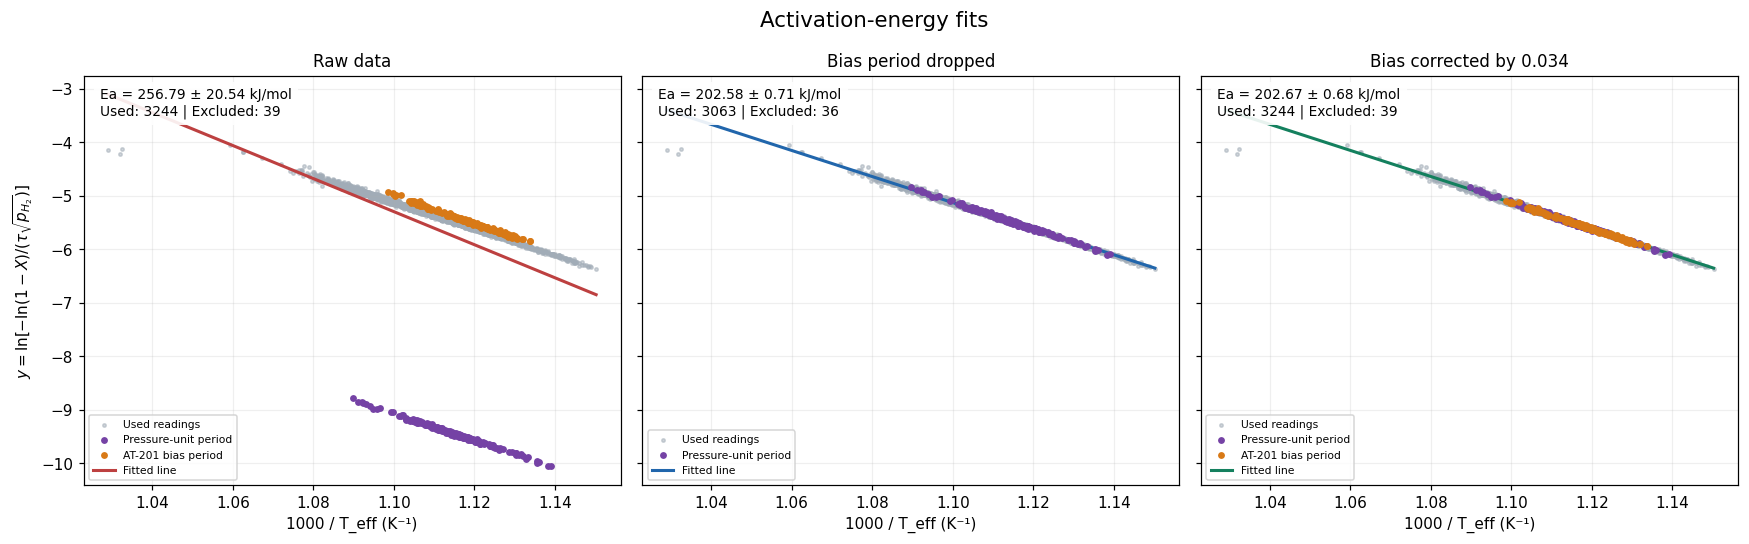

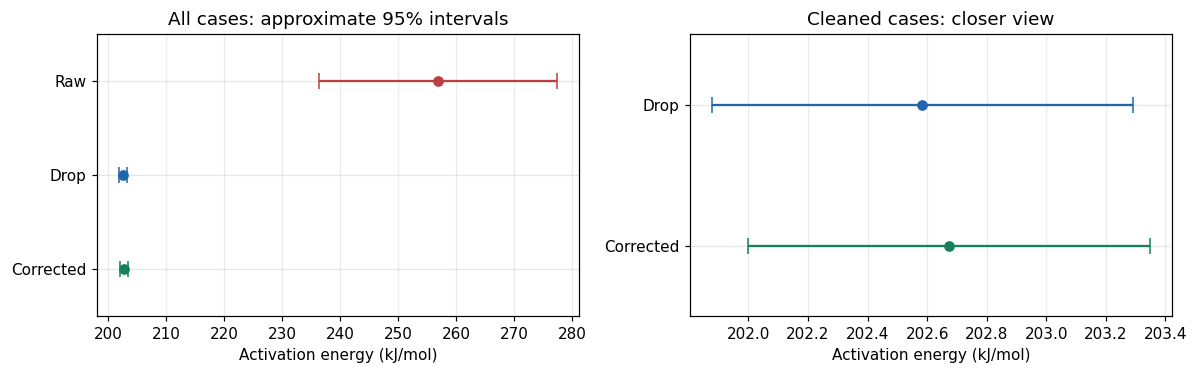

Excluded: missing inputs or conversion outside 0.02 < X < 0.99 (plus nonpositive physical inputs).
Intervals use the notebook's OLS method; they do not include cleaning uncertainty or time correlation.


In [ ]:
def arrhenius_fit(d):
    z = d.dropna(subset=["T_eff_K", "tau_s", "pH2_bar", "X_tol_AT201"])
    z = z.loc[(z.X_tol_AT201 > 0.02) & (z.X_tol_AT201 < 0.99)
              & (z.T_eff_K > 0) & (z.tau_s > 0) & (z.pH2_bar > 0)]
    x = 1 / z.T_eff_K.to_numpy()
    y = np.log(-np.log1p(-z.X_tol_AT201) / (z.tau_s * np.sqrt(z.pH2_bar))).to_numpy()
    A = np.column_stack([np.ones(len(x)), x])
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    residual = y - A @ b
    variance = residual @ residual / (len(x) - 2)
    slope_se = np.sqrt(variance * np.linalg.inv(A.T @ A)[1, 1])
    return {"Ea": -b[1] * 8.314 / 1000,
            "half_ci": 1.96 * slope_se * 8.314 / 1000,
            "beta": b, "x": x, "y": y, "data": z,
            "n": len(z), "excluded": len(d) - len(z)}


case_data = {"raw": rawf, "drop": datasets["drop"], "corrected": datasets["corrected"]}
arrhenius_results = {name: arrhenius_fit(data) for name, data in case_data.items()}
labels = {"raw": "Raw data", "drop": "Bias period dropped", "corrected": "Bias corrected by 0.034"}
colors = {"raw": "#bd4040", "drop": "#2166ac", "corrected": "#14805e"}

arrhenius_summary = pd.DataFrame([
    {"Case": name, "Used": r["n"], "Excluded": r["excluded"],
     "Ea (kJ/mol)": round(r["Ea"], 3),
     "95% interval": f'{r["Ea"]-r["half_ci"]:.3f} to {r["Ea"]+r["half_ci"]:.3f}'}
    for name, r in arrhenius_results.items()
]).set_index("Case")
display(arrhenius_summary)

Ea_raw = arrhenius_results["raw"]["Ea"]
Ea_drop, beta_drop = arrhenius_results["drop"]["Ea"], arrhenius_results["drop"]["beta"].copy()
Ea_corrected, beta_corrected = arrhenius_results["corrected"]["Ea"], arrhenius_results["corrected"]["beta"].copy()
Ea, beta = Ea_drop, beta_drop.copy()  # Compatibility with original single-case cells.

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, r) in zip(axes, arrhenius_results.items()):
    ax.scatter(1000*r["x"], r["y"], s=5, color="#a1acb7", alpha=.5, label="Used readings")
    for start, end, color, label in [
        (PSIG_START, PSIG_END, "#7542a5", "Pressure-unit period"),
        (BIAS_START, BIAS_END, "#d87916", "AT-201 bias period"),
    ]:
        if start is not None and end is not None:
            m = r["data"].timestamp.between(pd.Timestamp(start), pd.Timestamp(end)).to_numpy()
            if m.any():
                ax.scatter(1000*r["x"][m], r["y"][m], s=12, color=color, label=label, zorder=3)
    xx = np.linspace(r["x"].min(), r["x"].max(), 100)
    ax.plot(1000*xx, r["beta"][0]+r["beta"][1]*xx, color=colors[name], lw=2, label="Fitted line")
    ax.set_title(labels[name], fontsize=11)
    ax.text(.03, .97, f'Ea = {r["Ea"]:.2f} ± {r["half_ci"]:.2f} kJ/mol\n'
            f'Used: {r["n"]} | Excluded: {r["excluded"]}', transform=ax.transAxes,
            va="top", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=.9))
    ax.set_xlabel("1000 / T_eff (K⁻¹)")
    ax.grid(True, alpha=.2)
    ax.legend(loc="lower left", fontsize=7)
axes[0].set_ylabel(r"$y=\ln[-\ln(1-X)/(\tau\sqrt{p_{H_2}})]$")
fig.suptitle("Activation-energy fits", fontsize=14)
fig.tight_layout()
plt.show()

fig_ci, ci_axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, names in zip(ci_axes, [["raw", "drop", "corrected"], ["drop", "corrected"]]):
    for j, name in enumerate(names):
        r = arrhenius_results[name]
        ax.errorbar(r["Ea"], j, xerr=r["half_ci"], fmt="o", color=colors[name], capsize=5)
    ax.set_yticks(range(len(names)), [n.capitalize() for n in names])
    ax.set_ylim(len(names)-.5, -.5)
    ax.set_xlabel("Activation energy (kJ/mol)")
    ax.grid(True, axis="x", alpha=.25)
ci_axes[0].set_title("All cases: approximate 95% intervals")
ci_axes[1].set_title("Cleaned cases: closer view")
fig_ci.tight_layout()
plt.show()
print("Excluded: missing inputs or conversion outside 0.02 < X < 0.99 (plus nonpositive physical inputs).")
print("Intervals use the notebook's OLS method; they do not include cleaning uncertainty or time correlation.")


**Additional test removing three points well outside of the best fit**

The three readings selected for this comparison:


,timestamp,T_in_C,T_out_C,X_tol_AT201
Point,,,,
A,2025-10-03 08:00:00,665.0,725.9,0.9872
B,2025-10-03 12:00:00,665.2,726.8,0.9842
C,2025-10-04 04:00:00,666.5,730.9,0.9873


Activation energy comparison (kJ/mol):


,Used,Ea before,Ea after,95% ±,Change
Case,,,,,
drop,3060,202.584,205.327,0.492,2.742
corrected,3241,202.673,205.307,0.475,2.634


Refitted parameters; slope uses 1/T:


,ln A,Slope,k(910 K) / k(900 K)
Case,,,
drop,22.038392,-24696.494088,1.351945
corrected,22.035770,-24694.102369,1.351906


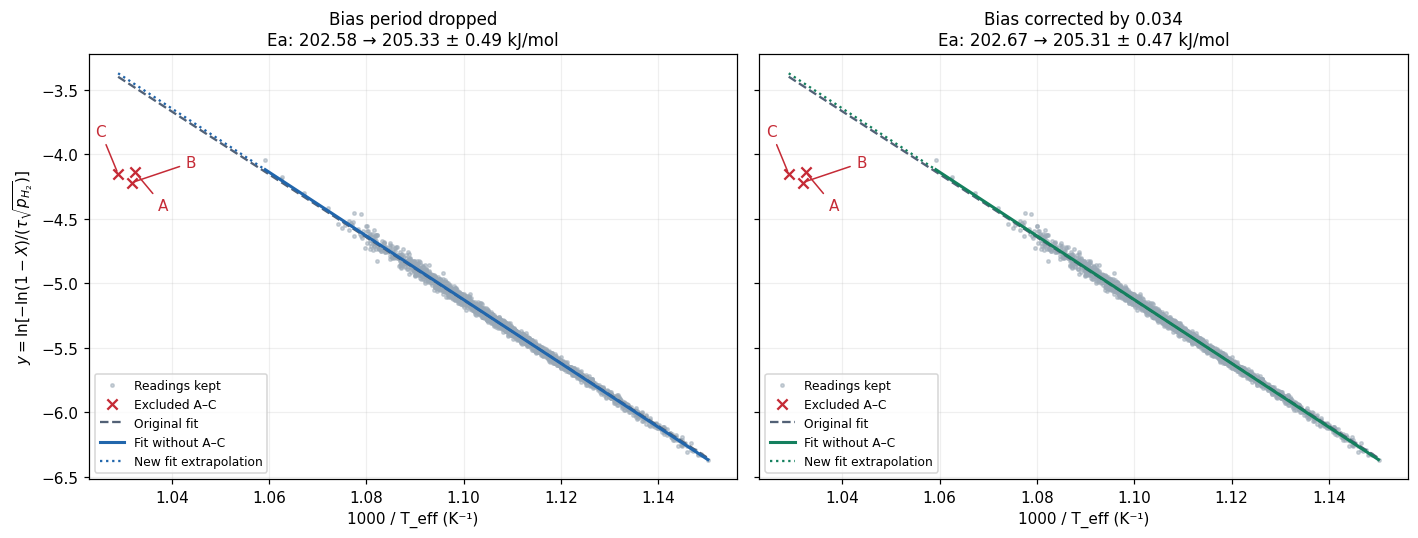

Original datasets/fits kept. New versions: datasets_no3 and arrhenius_results_no3.
The excluded readings belong to a real temperature trial; exclusion tests fit sensitivity.


In [ ]:
used_raw = arrhenius_results["raw"]["data"]
identified_points = used_raw.loc[1000 / used_raw.T_eff_K < 1.04].sort_values("timestamp").copy()
if len(identified_points) != 3:
    raise ValueError("Expected three isolated points. Check the preceding plot and datasets.")
identified_points["Point"] = ["A", "B", "C"]
print("The three readings selected for this comparison:")
display(identified_points.set_index("Point")[["timestamp", "T_in_C", "T_out_C", "X_tol_AT201"]])


remove_times = identified_points.timestamp
datasets_no3 = {
    name: data.loc[~data.timestamp.isin(remove_times)].copy().reset_index(drop=True)
    for name, data in datasets.items()
}
arrhenius_results_no3 = {name: arrhenius_fit(data) for name, data in datasets_no3.items()}

comparison_no3 = pd.DataFrame([
    {"Case": name, "Used": r["n"], "Ea before": arrhenius_results[name]["Ea"],
     "Ea after": r["Ea"], "95% ±": r["half_ci"],
     "Change": r["Ea"] - arrhenius_results[name]["Ea"]}
    for name, r in arrhenius_results_no3.items()
]).set_index("Case")
print("Activation energy comparison (kJ/mol):")
display(comparison_no3.round(3))

parameters_no3 = pd.DataFrame([
    {"Case": name, "ln A": r["beta"][0], "Slope": r["beta"][1],
     "k(910 K) / k(900 K)": np.exp(r["Ea"] * 1000 / 8.314 * (1/900 - 1/910))}
    for name, r in arrhenius_results_no3.items()
]).set_index("Case")
print("Refitted parameters; slope uses 1/T:")
display(parameters_no3.round(6))

Ea_drop_no3 = arrhenius_results_no3["drop"]["Ea"]
Ea_corrected_no3 = arrhenius_results_no3["corrected"]["Ea"]
beta_drop_no3 = arrhenius_results_no3["drop"]["beta"].copy()
beta_corrected_no3 = arrhenius_results_no3["corrected"]["beta"].copy()


fig_no3, axes_no3 = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
point_ids = identified_points.set_index("timestamp").Point.to_dict()
offsets = {"A": (15, -25), "B": (35, 10), "C": (-15, 25)}
for ax, (name, new) in zip(axes_no3, arrhenius_results_no3.items()):
    old = arrhenius_results[name]
    m = old["data"].timestamp.isin(remove_times).to_numpy()
    ax.scatter(1000*new["x"], new["y"], s=5, color="#9ba9b6", alpha=.5, label="Readings kept")
    ax.scatter(1000*old["x"][m], old["y"][m], s=45, marker="x", color="#c52b36", label="Excluded A–C")
    for t, x, y in zip(old["data"].loc[m, "timestamp"], 1000*old["x"][m], old["y"][m]):
        point = point_ids[t]
        ax.annotate(point, (x, y), xytext=offsets[point], textcoords="offset points",
                    color="#c52b36", fontsize=10, arrowprops=dict(arrowstyle="-", color="#c52b36"))
    xx = np.linspace(old["x"].min(), old["x"].max(), 100)
    ax.plot(1000*xx, old["beta"][0]+old["beta"][1]*xx, "--", color="#526176", lw=1.5, label="Original fit")
    xx_new = np.linspace(new["x"].min(), new["x"].max(), 100)
    ax.plot(1000*xx_new, new["beta"][0]+new["beta"][1]*xx_new, color=colors[name], lw=2, label="Fit without A–C")
    extension = np.linspace(old["x"].min(), new["x"].min(), 30)
    ax.plot(1000*extension, new["beta"][0]+new["beta"][1]*extension,
            color=colors[name], ls=":", lw=1.5, label="New fit extrapolation")
    ax.set_title(f'{labels[name]}\nEa: {old["Ea"]:.2f} → {new["Ea"]:.2f} ± {new["half_ci"]:.2f} kJ/mol', fontsize=11)
    ax.set_xlabel("1000 / T_eff (K⁻¹)")
    ax.grid(True, alpha=.2)
    ax.legend(loc="lower left", fontsize=8)
axes_no3[0].set_ylabel(r"$y=\ln[-\ln(1-X)/(\tau\sqrt{p_{H_2}})]$")
fig_no3.tight_layout()
plt.show()
print("Original datasets/fits kept. New versions: datasets_no3 and arrhenius_results_no3.")
print("The excluded readings belong to a real temperature trial; exclusion tests fit sensitivity.")


### ❓ Q2 · Activation energy (graded, 15 %)
(a) Report **your** $E_a$ with its 95 % interval, and the raw-data value. Explain *quantitatively* which cleaning step changed it most and why — trace the mechanism through the equations of Step 4 (which feature does that error corrupt, and in which direction?).
(b) Compare your $E_a$ with a published value for the thermal HDA reaction. Cite the source (book, table or equation number). Is your value consistent?
(c) Using your fit, by what factor does $k$ change when $T_{eff}$ rises from 900 K to 910 K? Show the calculation.
(d) Justify your `BIAS_ACTION` choice: re-run Step 3 with the other option and report how $E_a$ changes.

✏️ **Your answer:**

a)
| Case | Ea ± 95% margin (kJ/mol) |
|---|---:|
| Raw | 256.79 ± 20.54 |
| Dropped AT-201 readings | 202.58 ± 0.71 |
| Corrected AT-201 readings | 202.67 ± 0.68 |

Frozen flash-temperature signal on TT-104 didn't have any effects on `Ea` since `T_flash_C_TT104` was never used in calculations. However, correcting pressure had a tremendous effect on `Ea` causing it to decrease from **256.79 ± 20.54** in raw data to **202.58 ± 0.71** in database where AT-201 readings were dropped and **202.67 ± 0.68** where AT-201 readings were corrected by 0.034. That can be explained by the following:

$$
P_{abs} = 100\,P_{barg} + 101.3$ kPa
$$

$$
p_{H_2} = \dfrac{P_{abs}}{100}\,\dfrac{r}{1+r}
$$

$$\tau = V_R / Q,\; Q = \dfrac{F(1+r)}{3600}\dfrac{RT_{eff}}{P_{abs}}$$

$$
y=\ln\left[\frac{-\ln(1-X)}{\tau\sqrt{p_{H_2}}}\right]
$$


As it can be seen from the formulae above, the wrong pressure units made absolute pressure too high. This made gas volume flow too low, residence time too high, and hydrogen partial pressure too high. Therefore, the denominator got too large. The affected points moved downward and distorted the fitted slope.

As for correction of conversion values, it had minimal effect overall with `Ea` value going up slightly and confidence level tightening a bit.

b)
| Source | Ea<br>(kJ/mol) | Reaction<br>method | How Ea was obtained<br>/ evidence | Short source<br>quote |
|---|---:|---|---|---|
| Matsui, Amano &<br>Tokuhisa (1959)<br>[1] | 179.9 | Thermal, homogeneous<br>gas phase; static reactor<br>with gas circulation;<br>580–650 °C,<br>subatmospheric pressure | Experimental rate constants<br>at different temperatures;<br>plot of log(k) against 1/T.<br>Original value:<br>43 kcal/mol. | “static reactor<br>with a circulating<br>device” |
| Earlier literature<br>reviewed in<br>US4298457A [2] | ≈188.3 | Thermal<br>hydrodealkylation<br>in hydrogen | Literature summary;<br>the passage does not specify<br>the individual experimental<br>methods. Original value:<br>approximately 45 kcal/mol. | “about<br>45 kcal/mol” |
| Tokuhisa et al.,<br>reported by<br>Tsuchiya et al.<br>(1959) [3] | 196.6 | Thermal;<br>static reactor at<br>atmospheric pressure | Earlier experimental result<br>quoted by Tsuchiya et al.;<br>original paper not<br>independently checked.<br>Original value: 47 kcal/mol. | “both static<br>and flow reactors” |
| Tokuhisa et al.,<br>reported by<br>Tsuchiya et al.<br>(1959) [3] | 208.4 | Thermal;<br>flow reactor at<br>atmospheric pressure | Earlier experimental result<br>quoted by Tsuchiya et al.;<br>original paper not<br>independently checked.<br>Original value: 49.8 kcal/mol. | “47 and<br>49.8kcal/mol,<br>respectively” |
| Silsby & Sawyer<br>(1956), reported<br>by Matsui et al.<br>[1] | 209.2<br>± 20.9 | Thermal; conventional<br>flow reactor; experiments<br>at 500–600 °C and<br>250 atm, and 700–950 °C<br>at atmospheric pressure | Reported Arrhenius expression<br>for a rate first order in<br>toluene and half order<br>in hydrogen. Original value:<br>50 ± 5 kcal/mol;<br>confidence level unspecified. | “conventional<br>flow reactor” |
| Turton et al.,<br>Table 20.1 [4] | 209.2 | Thermal, noncatalytic;<br>kinetics used for an<br>adiabatic plug-flow<br>reactor | Calculated from the textbook<br>exponent −25,164/T using<br>Ea = 25,164R;<br>not a new experimental<br>determination. | “exp<br>(−25,164/T)” |
| Zimmerman & York<br>(1964) [5] | 213.0 | Thermal;<br>continuous-flow reactor;<br>700–950 °C at<br>atmospheric pressure | Experimental Arrhenius<br>expressions for toluene<br>disappearance and benzene<br>formation. Original value:<br>50,900 cal/mol. | “continuous<br>flow reactor” |
| GAMS HDA<br>model [6] | 217.6 | Process simulation using<br>plug-flow reactor models;<br>isothermal or adiabatic<br>with average temperature | Calculated from the<br>implemented exponent<br>−26,167/T using<br>Ea = 26,167R;<br>a model parameter. | “exp(-26167./<br>(rctt(rct)\*100.))” |
| Tsuchiya et al.<br>(1959) [3] | 228.0 | Thermal; continuous-flow<br>tubular reactor with<br>stainless-steel Raschig<br>rings; approximately<br>580–680 °C, 10–50 atm,<br>H₂/toluene = 4 | Product analysis by gas<br>chromatography; rate constants<br>calculated from conversion;<br>Ea obtained from an<br>Arrhenius plot.<br>Original value: 54.5 kcal/mol. | “activation energy<br>was determined as<br>54,500 cal/mol” |
| COMSOL HDA<br>model, Table 1<br>[7] | 228.2 | Thermal reaction simulated<br>in tubular and membrane<br>plug-flow reactors;<br>membrane supplies<br>additional hydrogen | Literature-derived Arrhenius<br>parameter supplied to the<br>simulation; not fitted<br>from new experiments. | “taken from<br>the literature” |
| Later literature<br>reviewed in<br>US4298457A [2] | 209.2–230.1 | Thermal<br>hydrodealkylation<br>of toluene | Literature range; the passage<br>does not specify each study's<br>reactor or fitting procedure.<br>Original range:<br>50–55 kcal/mol. | “50-55 kcal/mol” |
| Turton et al.,<br>Example 6.5,<br>citing Tarhan [4] | 148.1 | Textbook example in the<br>context of catalytic HDA;<br>catalyst not specified<br>in this example | Cited activation energy used<br>to calculate temperature<br>sensitivity; the example<br>does not describe its<br>experimental determination. | “148.1 kJ/mol” |
| Al-Khowaiter<br>(1995) [8] | 97.9 | Catalytic; 6% Ni/Al₂O₃;<br>pulse technique under<br>differential reactor<br>conditions | Experimental kinetic study;<br>low-conversion rates<br>interpreted using empirical<br>power-law and<br>Langmuir–Hinshelwood<br>equations. | “pulse technique<br>at differential<br>reactor conditions” |
| Posada-Borbón,<br>Möslinger &<br>Grönbeck (2026)<br>[9] | ≈482.4 | Catalytic computational<br>study on Pt(111);<br>hydrodemethylation<br>considered as a competing<br>reaction in an organic<br>hydrogen-carrier system | Density functional theory<br>combined with mean-field<br>microkinetic modelling.<br>Apparent Ea ≈5 eV under<br>the specified low-temperature<br>model conditions;<br>not a universal HDA value. | “∼5 eV from<br>380 K onward” |


[1]: https://www.jstage.jst.go.jp/article/jpi1959/1/0/1_0_67/_pdf/-char/en
[2]: https://patents.google.com/patent/US4298457A/en
[3]: https://www.jstage.jst.go.jp/article/jpi1959/1/0/1_0_73/_pdf/-char/en
[4]: https://dokumen.pub/analysis-synthesis-and-design-of-chemical-processes-originally-published-upper-saddle-river-nj-prentice-hall-c1998-3rd-ed-0135129664-9780135129661-9780135072912-0135072913.html
[5]: https://doi.org/10.1021/i260011a013
[6]: https://www.gams.com/53/gamslib_ml/libhtml/gamslib_hda.html
[7]: https://doc.comsol.com/6.4/doc/com.comsol.help.models.chem.membrane_hda/membrane_hda.html
[8]: https://agjsr.agu.edu.bh/publications/paper/1017
[9]: https://doi.org/10.1021/acscatal.6c01477


**Notes**
- All activation energies are expressed in kJ/mol.
- Conversions use 1 kcal = 4.184 kJ and 1 eV per molecule ≈ 96.485 kJ/mol.
- Quoted earlier studies and literature summaries are identified explicitly; they are not independent measurements by the source reporting them.
- Thermal, catalytic and computational apparent activation energies describe different conditions and should be compared separately.
- Everything is referenced.

Published activation energies for thermal HDA range from approximately 180 to 230 kJ/mol, depending on the study and operating conditions. Our estimates of 202.58 kJ/mol (dropped) and 202.67 kJ/mol (corrected) fall within this published range. Therefore these results are plausible for thermal HDA, although differences in operating conditions and model assumptions can explain differences between individual values.

c)
$$
\frac{k_{910}}{k_{900}}
=
\exp\left[\frac{E_a}{R}\left(\frac{1}{900}-\frac{1}{910}\right)\right]
$$

**Dropped case: $E_a = 202.58\ \mathrm{kJ/mol}$**

$$
\frac{k_{910}}{k_{900}}
=
\exp\left[\frac{202580}{8.314}\left(\frac{1}{900}-\frac{1}{910}\right)\right]
=
1.3465
$$

$$
\%\text{ increase}=(1.3465-1)\times100=\boxed{34.65\%}
$$

**Corrected case: $E_a = 202.67\ \mathrm{kJ/mol}$**

$$
\frac{k_{910}}{k_{900}}
=
\exp\left[\frac{202670}{8.314}\left(\frac{1}{900}-\frac{1}{910}\right)\right]
=
1.3467
$$

$$
\%\text{ increase}=(1.3467-1)\times100=\boxed{34.67\%}
$$

d) Correction is reasonable because the energy check supports a positive offset, and correction retains the affected rows. However, I have to state that 0.034 remains an estimated offset.

Changing from dropping to correcting changes Ea by only:
$$
202.673-202.584=0.089\ \mathrm{kJ/mol}
$$
Therefore, the choice has little effect on the fitted activation energy. I will keep the dropped case as a check.

## Step 6 · Machine-learning model for conversion
📘 We compare three models for $X$:
* **M1 Linear** on raw tags — a baseline.
* **M2 Random forest** on raw tags — flexible, no physics.
* **M3 Physics model** — the two-parameter Arrhenius fit from Step 5, used to predict X.

**Validation matters.** A *random* split puts neighbouring 4-hour samples (almost identical) in both train and test, so it rewards memorisation. A **time-based split** (train on the first 70 %, test on the last 30 %) mimics real use: predicting the future from the past.

In [ ]:
feats_raw = ["T_in_C", "P_R_barg", "H2_tol_ratio", "F_tol_kmolh"]
needed = feats_raw + ["X_tol_AT201", "T_eff_K", "tau_s", "pH2_bar"]
d6 = (df_corrected.replace([np.inf, -np.inf], np.nan)
      .dropna(subset=needed).sort_values("timestamp").reset_index(drop=True))
d6 = d6[(d6.T_eff_K > 0) & (d6.tau_s > 0) & (d6.pH2_bar > 0)]
cut = int(0.7 * len(d6))
tr, te = d6.iloc[:cut], d6.iloc[cut:]
a, b = train_test_split(d6, test_size=0.3, random_state=0)

# Fit Arrhenius parameters using ONLY the time-training data.
fit_tr = tr[tr.X_tol_AT201.between(0.02, 0.99, inclusive="neither")]
x = 1 / fit_tr.T_eff_K.to_numpy()
y = np.log(-np.log1p(-fit_tr.X_tol_AT201) / (fit_tr.tau_s * np.sqrt(fit_tr.pH2_bar)))
beta_train = np.linalg.lstsq(np.c_[np.ones(len(x)), x], y, rcond=None)[0]

def physics_X(d):
    Da = np.exp(beta_train[0] + beta_train[1] / d.T_eff_K) * d.tau_s * np.sqrt(d.pH2_bar)
    return -np.expm1(-Da)

rows = []
for split, train, test in [("time split", tr, te), ("random split", a, b)]:
    for name, mdl in [
        ("M1 linear", LinearRegression()),
        ("M2 random forest", RandomForestRegressor(
            300, min_samples_leaf=3, random_state=0, n_jobs=-1))
    ]:
        mdl.fit(train[feats_raw], train.X_tol_AT201)
        pred = mdl.predict(test[feats_raw])
        rows.append([name, split, r2_score(test.X_tol_AT201, pred),
                     mean_absolute_error(test.X_tol_AT201, pred)])
        if name == "M2 random forest" and split == "time split":
            rf_X = mdl
pX = physics_X(te)
rows.append(["M3 physics (2 parameters)", "time split",
             r2_score(te.X_tol_AT201, pX), mean_absolute_error(te.X_tol_AT201, pX)])
display(pd.DataFrame(rows, columns=["model", "validation", "R2", "MAE"]).round(4))

,model,validation,R2,MAE
0,M1 linear,time split,0.8856,0.0328
1,M2 random forest,time split,0.9650,0.0182
2,M1 linear,random split,0.8657,0.0265
3,M2 random forest,random split,0.9848,0.0106
4,M3 physics (2 parameters),time split,0.9975,0.0048


## Step 7 · What controls conversion? Importance and confounding
📘 **Permutation importance** measures how much the model's error grows when one feature is shuffled. It tells you what the *model* uses — not necessarily what *causes* the change. If two inputs move together in the plant (because of an operating policy), the model can credit either one.

Look at the correlation matrix first, then the partial-dependence curves (the model's average prediction as one feature varies).

,T_in_C,P_R_barg,H2_tol_ratio,F_tol_kmolh
T_in_C,1.000,-0.019,0.011,0.095
P_R_barg,-0.019,1.000,0.822,-0.036
H2_tol_ratio,0.011,0.822,1.000,0.009
F_tol_kmolh,0.095,-0.036,0.009,1.000


,permutation importance
T_in_C,1.3686
H2_tol_ratio,0.3333
F_tol_kmolh,0.0560
P_R_barg,0.0030


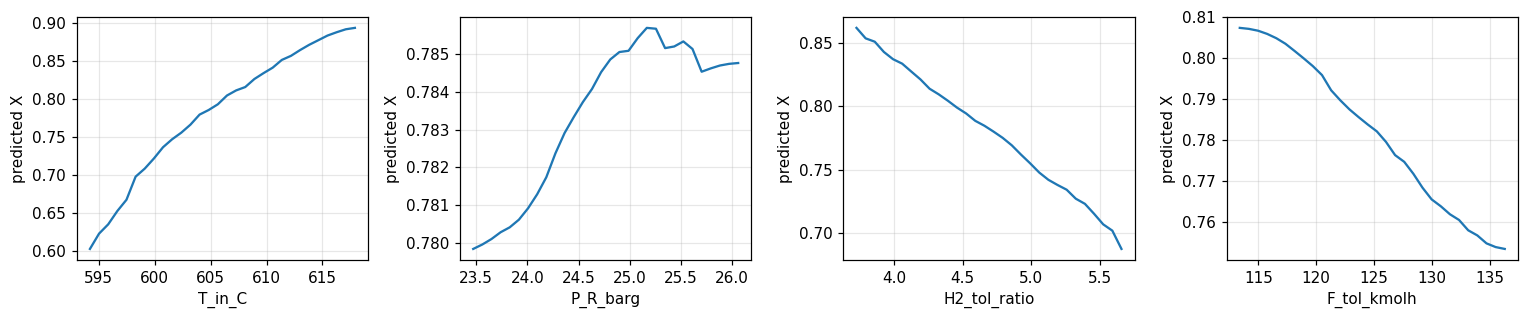

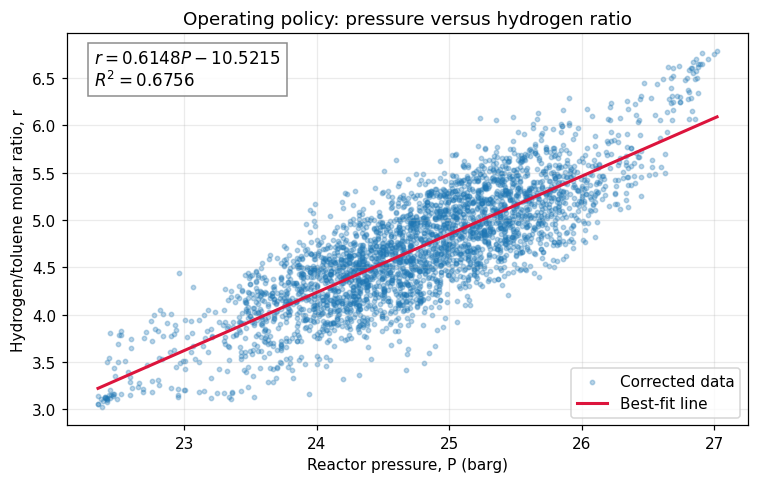

Slope: 0.6148 ratio units per barg
Intercept: -10.5215
R²: 0.6756


In [ ]:
# Correlation and permutation importance
display(d6[feats_raw].corr().round(3))

imp = permutation_importance(
    rf_X, te[feats_raw], te.X_tol_AT201,
    n_repeats=10, random_state=0
)
display(
    pd.Series(imp.importances_mean, index=feats_raw)
    .sort_values(ascending=False).round(4)
    .to_frame("permutation importance")
)

# Partial-dependence plots
fig, axs = plt.subplots(1, 4, figsize=(14, 3))
for ax, f in zip(axs, feats_raw):
    pdp = partial_dependence(
        rf_X, d6[feats_raw], [f], grid_resolution=30
    )
    gv = pdp["grid_values"] if "grid_values" in pdp else pdp["values"]
    ax.plot(gv[0], pdp["average"][0])
    ax.set_xlabel(f)
    ax.set_ylabel("predicted X")
plt.tight_layout()
plt.show()

# Best-fit line: hydrogen ratio = slope × pressure + intercept
policy_fit = LinearRegression().fit(d6[["P_R_barg"]], d6.H2_tol_ratio)
slope = policy_fit.coef_[0]
intercept = policy_fit.intercept_
policy_r2 = policy_fit.score(d6[["P_R_barg"]], d6.H2_tol_ratio)

P = np.linspace(d6.P_R_barg.min(), d6.P_R_barg.max(), 100)
equation = f"$r = {slope:.4f}P {intercept:+.4f}$"

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(d6.P_R_barg, d6.H2_tol_ratio,
           s=8, alpha=0.3, label="Corrected data")
ax.plot(P, slope * P + intercept,
        color="crimson", linewidth=2, label="Best-fit line")
ax.text(
    0.04, 0.96, equation + f"\n$R^2 = {policy_r2:.4f}$",
    transform=ax.transAxes, va="top", fontsize=11,
    bbox=dict(facecolor="white", edgecolor="grey", alpha=0.9)
)
ax.set_xlabel("Reactor pressure, P (barg)")
ax.set_ylabel("Hydrogen/toluene molar ratio, r")
ax.set_title("Operating policy: pressure versus hydrogen ratio")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Slope: {slope:.4f} ratio units per barg")
print(f"Intercept: {intercept:.4f}")
print(f"R²: {policy_r2:.4f}")

**For Q3 (c)**

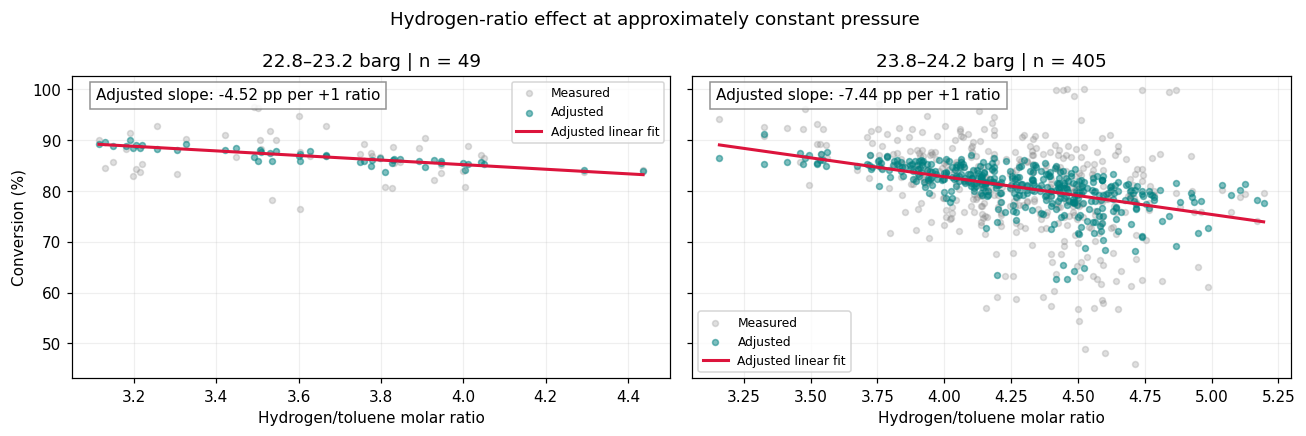

,Pressure band (barg),Readings,Mean pressure (barg),Raw slope (pp / +1 ratio),Adjusted slope (pp / +1 ratio)
0,22.8–23.2,49,22.9986,-2.8845,-4.5187
1,23.8–24.2,405,24.0255,-9.6005,-7.4385


In [ ]:
inputs = ["H2_tol_ratio", "T_eff_K", "F_tol_kmolh", "P_R_barg"]
target = "X_tol_AT201"
data = (df_corrected[inputs + [target]]
        .replace([np.inf, -np.inf], np.nan).dropna())
width = 0.2  # Pressure bands: 22.8–23.2 and 23.8–24.2 barg

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
results = []

for ax, pressure in zip(axes, [23, 24]):
    g = data[data.P_R_barg.between(pressure - width, pressure + width)].copy()
    if len(g) < 10 or g.H2_tol_ratio.nunique() < 2:
        ax.set_title(f"Near {pressure} barg: too few readings")
        continue

    model = LinearRegression().fit(g[inputs], g[target])
    raw_slope = np.polyfit(g.H2_tol_ratio, g[target], 1)[0]

    fixed = g[inputs].copy()
    for c in inputs[1:]:
        fixed[c] = g[c].median()
    adjusted = g[target] - model.predict(g[inputs]) + model.predict(fixed)

    curve = pd.DataFrame({c: np.repeat(g[c].median(), 100) for c in inputs})
    curve["H2_tol_ratio"] = np.linspace(
        g.H2_tol_ratio.min(), g.H2_tol_ratio.max(), 100
    )
    slope = model.coef_[0] * 100  # Percentage points per +1 hydrogen ratio

    ax.scatter(g.H2_tol_ratio, g[target] * 100,
               s=15, color="grey", alpha=0.25, label="Measured")
    ax.scatter(g.H2_tol_ratio, adjusted * 100,
               s=15, color="teal", alpha=0.5, label="Adjusted")
    ax.plot(curve.H2_tol_ratio, model.predict(curve) * 100,
            color="crimson", lw=2, label="Adjusted linear fit")
    ax.set_title(f"{pressure-width:.1f}–{pressure+width:.1f} barg | n = {len(g)}")
    ax.set_xlabel("Hydrogen/toluene molar ratio")
    ax.text(
        0.04, 0.96, f"Adjusted slope: {slope:+.2f} pp per +1 ratio",
        transform=ax.transAxes, va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="grey")
    )
    ax.grid(alpha=0.2)
    ax.legend(loc="best", fontsize=8)

    results.append({
        "Pressure band (barg)": f"{pressure-width:.1f}–{pressure+width:.1f}",
        "Readings": len(g),
        "Mean pressure (barg)": g.P_R_barg.mean(),
        "Raw slope (pp / +1 ratio)": raw_slope * 100,
        "Adjusted slope (pp / +1 ratio)": slope
    })

axes[0].set_ylabel("Conversion (%)")
fig.suptitle("Hydrogen-ratio effect at approximately constant pressure")
plt.tight_layout()
plt.show()
display(pd.DataFrame(results).round(4))

### ❓ Q3 · Pressure, hydrogen ratio and confounding (graded, 15 %)
(a) Report the correlation between `P_R_barg` and `H2_tol_ratio` in **your** data and the slope of the policy line in the scatter plot (fit it).
(b) The main reaction has Δn = 0, yet pressure affects conversion in your data. Using the Step 4 equations, predict the **sign** of ∂X/∂P at constant T, r and F through (i) residence time and (ii) $p_{H_2}$. Then use the physics model `physics_X` to compute X at two pressures 1 bar apart (other variables at their median) and report the change.
(c) Does the random forest's ranking of `P_R_barg` vs `H2_tol_ratio` agree with (b)? Design and run **one** test that separates the two effects (e.g. stratify by narrow pressure bands and look at the ratio effect inside each band). Show the output and conclude.

✏️ **Your answer:**

**A**

Correlation factor between `P_R_barg` and `H2_tol_ratio` is 0.822 and slope the of the best fit line is 0.6148 with $R^{2}$ being 0.6756 indicating that there is a **positive association** between those two but nothing can be said on causality between them.

**B**

**i. Residence time**

$$
Q=\frac{\dot nRT}{P_{\mathrm{abs}}},
\qquad
\tau=\frac{V_R}{Q}
$$

Higher pressure reduces gas volume flow and increases residence time, giving more time for reaction.

**ii. Hydrogen partial pressure**

$$
p_{H_2}=\frac{P_{\mathrm{abs}}}{100}\frac{r}{1+r}
$$

Here, $P_{\mathrm{abs}}$ is in kPa and $p_{H_2}$ is in bar. Higher pressure increases hydrogen partial pressure and reaction rate through **rate ∝ $\sqrt{p_{H_2}}$**

Both effects increase conversion:

$$
\boxed{\left(\frac{\partial X}{\partial P}\right)_{T,r,F}>0}
$$

**3. Numerical calculation**

Keep the other conditions at their median values:

$$
T=901.45\ \mathrm K,\quad
r=4.7055,\quad
F=124.09\ \mathrm{kmol/h}
$$

The Step 6 training-only fit gives:

$$
k=\exp\left(21.52115-\frac{24231.0136}{901.45}\right)
\approx0.00470614
$$

Using $P_{\mathrm{abs}}=100P_{\mathrm{barg}}+101.325$, $V_R=40\ \mathrm{m^3}$ and the equations above:

| Quantity | At 24.8 barg | At 25.8 barg |
|---|---:|---:|
| Absolute pressure, kPa | 2581.325 | 2681.325 |
| Gas volume flow, m³/s | 0.571001 | 0.549706 |
| Residence time, s | 70.0524 | 72.7662 |
| Hydrogen partial pressure, bar | 21.28898 | 22.11371 |

Predict conversion using:

$$
X=1-\exp\left[-k\tau\sqrt{p_{H_2}}\right]
$$

$$
X_1=1-\exp\left[-0.00470614(70.0524)\sqrt{21.28898}\right]
=0.781534
$$

$$
X_2=1-\exp\left[-0.00470614(72.7662)\sqrt{22.11371}\right]
=0.800186
$$

$$
\Delta X=0.800186-0.781534=0.018652
$$

**A 1 bar increase raises predicted conversion by 1.87 percentage points**, from 78.15% to 80.02%.

Although $\Delta n=0$ means pressure does not directly shift ideal-gas equilibrium, it still affects residence time and reaction rate.

**C**

**Not directly.** In part (b), increasing pressure by 1 bar raised predicted conversion by **1.87 percentage points**. However, the random forest gives pressure much lower importance (**0.0030**) than hydrogen ratio (**0.3333**). Because these inputs usually increase together (correlation **0.822**), the model may use hydrogen ratio to represent some of pressure’s effect.

To separate them, I tested two narrow pressure bands and adjusted for temperature, feed rate and small pressure differences:

| Pressure band | Readings | Conversion change per +1 hydrogen ratio |
|---|---:|---:|
| 22.8–23.2 barg | 49 | −4.52 percentage points |
| 23.8–24.2 barg | 405 | −7.44 percentage points |

Conversion decreases with hydrogen ratio even when pressure is nearly constant. This supports a separate hydrogen-ratio effect, consistent with higher gas flow reducing residence time. The forest’s low pressure importance therefore does not mean pressure has little physical effect.

## Step 8 · Benzene loss at the flash: the season is a process condition
📘 V-102 is cooled with cooling-tower water, so its temperature follows the weather. By Raoult's law the benzene mole fraction in the purge gas is

$$y_B = K_B\,x_B,\qquad K_B = \frac{P^{sat}_B(T_{flash})}{P_{flash}}$$

so the loss should scale with $K_B$. A model with the physics feature $K_B$ should need far fewer inputs than one with raw tags.

Physics model: loss = 0.0741 × K_B × F × r
R² on fitted data = 0.985
Valid readings: 3,127 of 3,283


,T_cw_C,T_flash_C_TT104,K_B_flash,benz_loss_purge_kmolh,Readings
month,,,,,
1,27.1426,34.6326,0.0079,0.3451,371
2,23.0360,30.5274,0.0065,0.3017,336
3,19.6019,27.1084,0.0057,0.2528,370
4,17.8825,25.3425,0.0052,0.2373,360
5,18.1832,25.7256,0.0054,0.2445,351
6,21.0362,28.5478,0.0060,0.2671,232
7,24.6094,32.1656,0.0073,0.2981,192
8,28.9602,36.4806,0.0090,0.3542,186
9,32.3860,39.8732,0.0101,0.4449,179


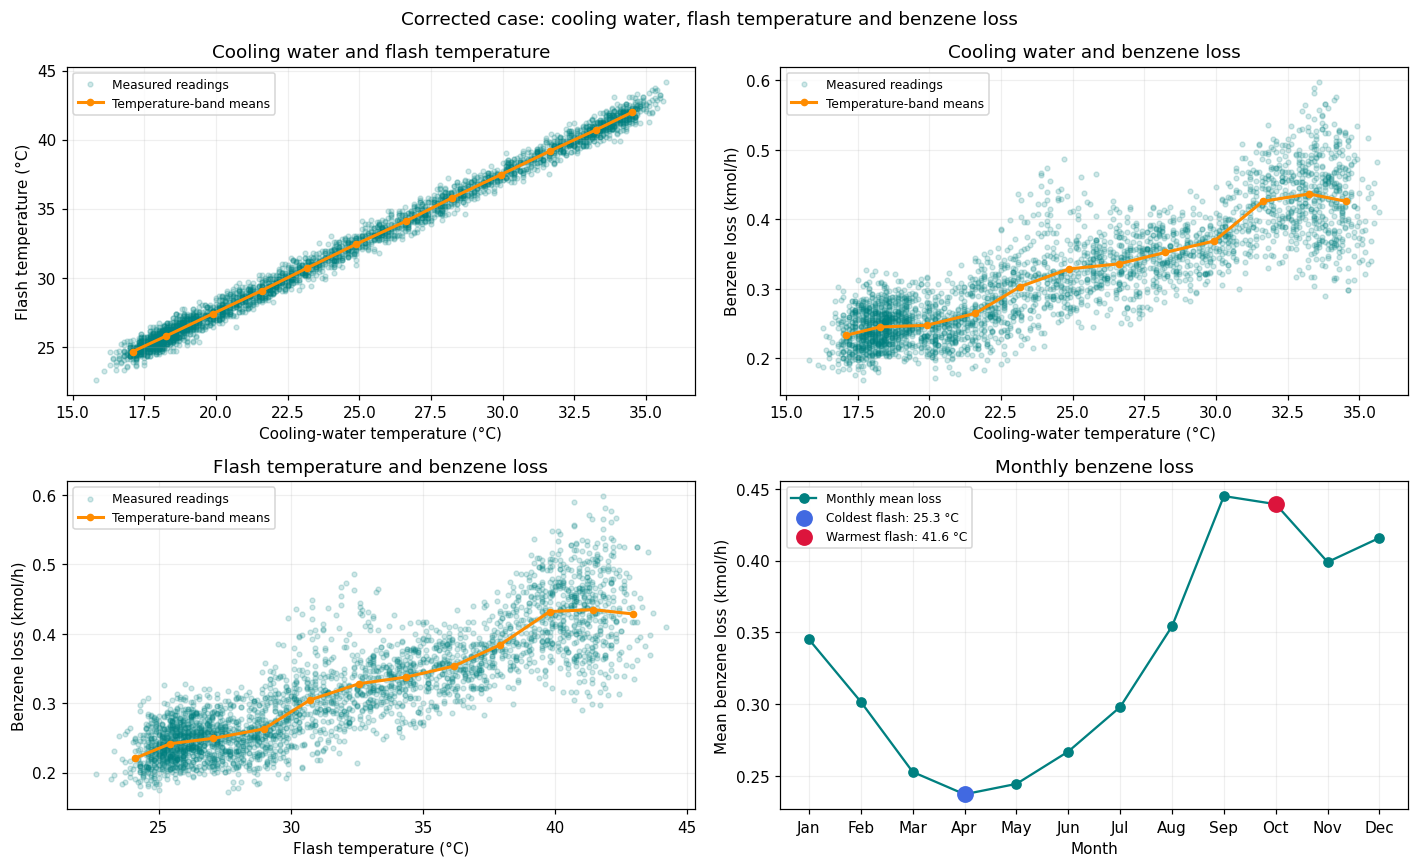

In [ ]:
# Prepare the corrected dataset.
required = ["timestamp", "T_cw_C", "T_flash_C_TT104", "K_B_flash",
            "benz_loss_purge_kmolh", "F_tol_kmolh", "H2_tol_ratio"]
d8 = df_corrected.copy()
d8["timestamp"] = pd.to_datetime(d8.timestamp, errors="coerce")
d8 = d8.replace([np.inf, -np.inf], np.nan).dropna(subset=required)
d8["purge_basis"] = d8.F_tol_kmolh * d8.H2_tol_ratio
d8["month"] = d8.timestamp.dt.month

# Physics model: loss = c × K_B × F × r.
basis = (d8.K_B_flash * d8.purge_basis).to_numpy().reshape(-1, 1)
lin = LinearRegression(fit_intercept=False).fit(
    basis, d8.benz_loss_purge_kmolh
)
pred = lin.predict(basis)
print(f"Physics model: loss = {lin.coef_[0]:.4f} × K_B × F × r")
print(f"R² on fitted data = {r2_score(d8.benz_loss_purge_kmolh, pred):.3f}")
print(f"Valid readings: {len(d8):,} of {len(df_corrected):,}")


cols = ["T_cw_C", "T_flash_C_TT104", "K_B_flash", "benz_loss_purge_kmolh"]
monthly = d8.groupby("month")[cols].mean()
monthly["Readings"] = d8.groupby("month").size()
display(monthly.round(4))

def relation(ax, x, y, xlabel, ylabel, title):
    ax.scatter(d8[x], d8[y], s=10, alpha=0.18,
               color="teal", label="Measured readings")
    bands = pd.cut(d8[x], bins=12, duplicates="drop")
    means = d8.groupby(bands, observed=True)[[x, y]].mean()
    ax.plot(means[x], means[y], "o-", color="darkorange",
            lw=2, ms=4, label="Temperature-band means")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig, axs = plt.subplots(2, 2, figsize=(13, 8))

relation(axs[0, 0], "T_cw_C", "T_flash_C_TT104",
         "Cooling-water temperature (°C)", "Flash temperature (°C)",
         "Cooling water and flash temperature")

relation(axs[0, 1], "T_cw_C", "benz_loss_purge_kmolh",
         "Cooling-water temperature (°C)", "Benzene loss (kmol/h)",
         "Cooling water and benzene loss")

relation(axs[1, 0], "T_flash_C_TT104", "benz_loss_purge_kmolh",
         "Flash temperature (°C)", "Benzene loss (kmol/h)",
         "Flash temperature and benzene loss")


ax = axs[1, 1]
ax.plot(monthly.index, monthly.benz_loss_purge_kmolh,
        "o-", color="teal", label="Monthly mean loss")
cold = monthly.T_flash_C_TT104.idxmin()
warm = monthly.T_flash_C_TT104.idxmax()

for month, color, label in [(cold, "royalblue", "Coldest"),
                            (warm, "crimson", "Warmest")]:
    ax.scatter(
        month, monthly.loc[month, "benz_loss_purge_kmolh"],
        s=100, color=color, zorder=3,
        label=f"{label} flash: {monthly.loc[month, 'T_flash_C_TT104']:.1f} °C"
    )

ax.set_xticks(monthly.index,
              [calendar.month_abbr[int(m)] for m in monthly.index])
ax.set(xlabel="Month", ylabel="Mean benzene loss (kmol/h)",
       title="Monthly benzene loss")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)

fig.suptitle("Corrected case: cooling water, flash temperature and benzene loss")
plt.tight_layout()
plt.show()

### ❓ Q4 · Seasonal benzene loss (graded, 15 %)
(a) From **your** monthly table, give the warmest and coldest months, their mean flash temperatures and mean losses, and the ratio of losses.
(b) Predict that ratio from Raoult's law alone using the two mean flash temperatures (show the Antoine calculation). Explain any difference from (a).
(c) Convert the summer excess loss into **tonnes of benzene per year** (M = 78.11 kg/kmol; state your operating-hours assumption).
(d) Propose one way to cut the summer loss. Using the Ch. 6 operating window and utility limits, state which **condition of special concern** your proposal creates and what it costs (equipment and operating). No vague answers: name the equipment.

✏️ **Your answer:**

**A**

| Month | Mean flash temperature (°C) | Mean benzene loss (kmol/h) |
|---|---:|---:|
| Warmest: October | 41.6215 | 0.4393 |
| Coldest: April | 25.3425 | 0.2373 |

The loss ratio is:

$$
LR=\frac{L_{\mathrm{October}}}{L_{\mathrm{April}}}
=\frac{0.4393}{0.2373}
\approx\boxed{1.85}
$$

The mean benzene loss in October is approximately **1.85 times** that in April, or **85% higher**.

**B**

For a temperature-only prediction, assume the same flash pressure, gas flow and liquid composition. Raoult’s law then gives:

$$
\boxed{\frac{L_w}{L_c}
\approx
\frac{P_w^{sat}}{P_c^{sat}}}
$$

Using the Antoine equation, with temperature in °C and vapour pressure in mmHg:

$$
P^{sat}=10^{\,6.90565-\frac{1211.033}{T_{flash}+220.79}}
$$

**October:**

$$
P_w^{sat}
=
10^{\,6.90565-\frac{1211.033}{41.6215+220.79}}
=
195.27\ \mathrm{mmHg}
$$

**April:**

$$
P_c^{sat}
=
10^{\,6.90565-\frac{1211.033}{25.3425+220.79}}
=
96.69\ \mathrm{mmHg}
$$

Therefore:

$$
\boxed{\frac{L_w}{L_c}\approx\frac{195.27}{96.69}=2.02}
$$

Temperature alone predicts **2.02 times** as much loss in October, compared with the measured ratio of **1.85**.

The difference occurs because other conditions also change. For example, October’s mean gas-flow proxy $Fr$ is lower than April’s (**551.9 versus 610.7 kmol/h**), which helps reduce the loss. Flash pressure also changes, so the temperature-only assumptions are not fully met.

**C**

I will use April as the cold-reference month from part (a). I am also going to assume that workload throughout a year is distributed equally.

The mean summer loss is (summer is defined here as a period of time **between June and August**):

$$
L_{\mathrm{summer}}
=\frac{0.2671+0.2981+0.3542}{3}
=0.3065\ \mathrm{kmol/h}
$$

The excess above April’s loss is:

$$
\Delta L=0.3065-0.2373=0.0692\ \mathrm{kmol/h}
$$

Assuming **8,000 operating hours/year**, summer operating hours are:

$$
H_{\mathrm{summer}}=8000\frac{3}{12}=2000\ \mathrm{h/year}
$$

Using benzene’s molar mass, $M=78.11\ \mathrm{kg/kmol}$:

$$
m_{\mathrm{excess}}
=\frac{\Delta L\,M\,H_{\mathrm{summer}}}{1000}
=\frac{0.0692(78.11)(2000)}{1000}
\approx\boxed{10.8\ \mathrm{tonnes/year}}
$$

Under these assumptions, summer operation causes approximately **10.8 extra tonnes of benzene loss per year**, compared with operating those hours at April’s mean loss rate.

**D**

I would install a **vapour-compression chiller with an insulated chilled-water loop** supplying the cooler upstream of V-102. This would lower the flash temperature and benzene vapour pressure, reducing benzene loss through the purge.

The **condition of special concern** is cooling below the temperature achievable with summer cooling-tower water. This requires refrigeration and additional electricity.

My equipment costs would include the chiller, circulation pump, insulated piping and any required cooler modifications. Operating costs would include compressor and pump electricity, maintenance and refrigerant servicing. Lower cooling temperatures generally increase compressor energy requirements.

Available electrical supply, cooler capacity and condenser heat-rejection capacity needs to be checked before choosing the cooling temperature, however.

## Step 9 · The production request: "run hotter"
📘 Production trained a random forest on the historian data to predict **conversion** (the number the control room watches on AT-201) and let a simple optimiser search the inlet temperature, holding the other inputs at their medians. We repeat their analysis, then train a second model on **benzene production** $F\,X\,S$ and compare. Finally we check both answers with physics and the plant data sheet.

An ML model only knows the region where it has data. Before trusting a prediction, count the training points near it.

Maximum conversion: T_in = 666 °C | X_RF = 0.992 | Benzene_RF = 75.02 kmol/h | Readings within ±5 °C: 25
Maximum benzene: T_in = 624 °C | X_RF = 0.939 | Benzene_RF = 110.46 kmol/h | Readings within ±5 °C: 90
Fitted adiabatic-rise parameter θ = 334.30 K


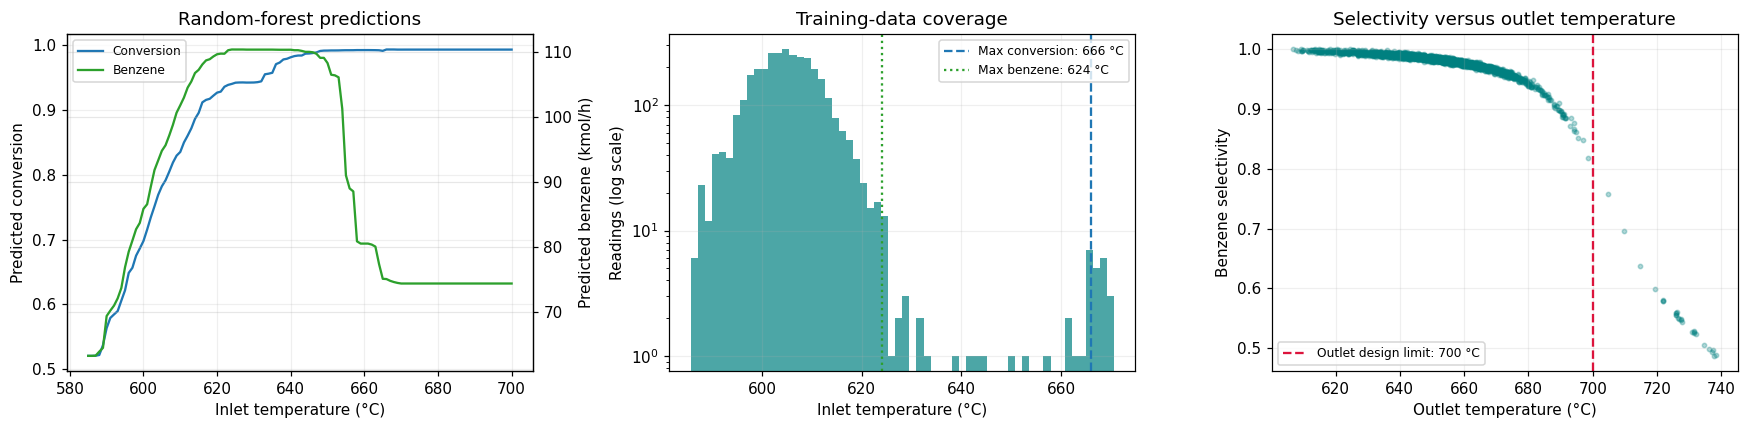

In [ ]:
feats_b = ["T_in_C", "P_R_barg", "H2_tol_ratio", "F_tol_kmolh"]
needed = feats_b + ["benzene_kmolh", "T_out_C", "S_benz", "X_tol_AT201"]
d9 = (df_corrected.replace([np.inf, -np.inf], np.nan)
      .dropna(subset=needed).sort_values("timestamp").reset_index(drop=True))

rf_Xp = RandomForestRegressor(
    400, min_samples_leaf=2, random_state=0, n_jobs=-1
).fit(d9[feats_b], d9.X_tol_AT201)

rf_B = RandomForestRegressor(
    400, min_samples_leaf=2, random_state=0, n_jobs=-1
).fit(d9[feats_b], d9.benzene_kmolh)

med = d9[feats_b].median()
grid = pd.DataFrame({"T_in_C": np.arange(585, 701, 1.0)})
for f in feats_b[1:]:
    grid[f] = med[f]

grid["X_pred_RF"] = rf_Xp.predict(grid[feats_b])
grid["benzene_pred_RF"] = rf_B.predict(grid[feats_b])
bestX = grid.loc[grid.X_pred_RF.idxmax()]
bestB = grid.loc[grid.benzene_pred_RF.idxmax()]

for label, point in [("Maximum conversion", bestX), ("Maximum benzene", bestB)]:
    n_near = d9.T_in_C.between(point.T_in_C - 5, point.T_in_C + 5).sum()
    print(f"{label}: T_in = {point.T_in_C:.0f} °C | "
          f"X_RF = {point.X_pred_RF:.3f} | "
          f"Benzene_RF = {point.benzene_pred_RF:.2f} kmol/h | "
          f"Readings within ±5 °C: {n_near}")

theta_c = ((d9.T_out_C - d9.T_in_C) * (1 + d9.H2_tol_ratio)
           / d9.X_tol_AT201.where(d9.X_tol_AT201 > 0)).median()
print(f"Fitted adiabatic-rise parameter θ = {theta_c:.2f} K")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax0b = ax[0].twinx()
l1 = ax[0].plot(grid.T_in_C, grid.X_pred_RF,
                color="tab:blue", label="Conversion")
l2 = ax0b.plot(grid.T_in_C, grid.benzene_pred_RF,
               color="tab:green", label="Benzene")
ax[0].set(xlabel="Inlet temperature (°C)", ylabel="Predicted conversion",
          title="Random-forest predictions")
ax0b.set_ylabel("Predicted benzene (kmol/h)")
ax[0].legend(l1 + l2, [line.get_label() for line in l1 + l2], fontsize=8)

ax[1].hist(d9.T_in_C, bins=60, color="teal", alpha=0.7)
ax[1].set_yscale("log")
ax[1].axvline(bestX.T_in_C, color="tab:blue", ls="--",
              label=f"Max conversion: {bestX.T_in_C:.0f} °C")
ax[1].axvline(bestB.T_in_C, color="tab:green", ls=":",
              label=f"Max benzene: {bestB.T_in_C:.0f} °C")
ax[1].set(xlabel="Inlet temperature (°C)", ylabel="Readings (log scale)",
          title="Training-data coverage")
ax[1].legend(fontsize=8)

ax[2].scatter(d9.T_out_C, d9.S_benz, s=8, alpha=0.3, color="teal")
ax[2].axvline(700, color="crimson", ls="--",
              label="Outlet design limit: 700 °C")
ax[2].set(xlabel="Outlet temperature (°C)", ylabel="Benzene selectivity",
          title="Selectivity versus outlet temperature")
ax[2].legend(fontsize=8)

for axis in ax:
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 📘 Physics check of a candidate operating point
The function below predicts X (physics model), the outlet temperature (energy balance with θ) and the H-101 duty for **any** candidate condition, then builds a mini **process conditions matrix** against the data sheet and the Ch. 6 operating window. Try the RF optima and at least two alternatives of your own. `onset` is the outlet temperature where selectivity starts to collapse — 690 °C is a placeholder; replace it with the value you find in Q5c.

In [ ]:
beta9 = arrhenius_results["corrected"]["beta"].copy()
hydrocracking_onset = 690.0

def check_point(T_in, P=None, r=None, F=None, onset=None):
    P = med.P_R_barg if P is None else P
    r = med.H2_tol_ratio if r is None else r
    F = med.F_tol_kmolh if F is None else F
    onset = hydrocracking_onset if onset is None else onset
    P_abs = 100 * P + 101.325
    X = 0.7

    for _ in range(200):
        T_out = T_in + theta_c * X / (1 + r)
        T_eff = (T_in + T_out) / 2 + 273.15
        tau = 40 / (F * (1 + r) / 3600 * 8.314 * T_eff / P_abs)
        pH2 = P_abs / 100 * r / (1 + r)
        k = np.exp(beta9[0] + beta9[1] / T_eff)
        X_new = -np.expm1(-k * tau * np.sqrt(pH2))
        if abs(X_new - X) < 1e-10:
            X = X_new
            break
        X = X_new
    else:
        raise RuntimeError(f"Calculation did not converge at {T_in} °C.")

    T_out = T_in + theta_c * X / (1 + r)
    duty = F * (1 + r) * 33.0 * (T_in - 225) / 3600
    pcm = {
        "High temperature (>250 °C)": T_out > 250,
        "Materials concern (>400 °C)": T_out > 400,
        "Outlet design limit: 700 °C": T_out > 700,
        "High pressure (>10 barg)": P > 10,
        "Pressure design limit: 28 barg": P > 28,
        "Heater limit: 3500 kW": duty > 3500,
        f"Hydrocracking concern: ≥{onset:g} °C": T_out >= onset
    }
    return {
        "T_in": T_in, "P_barg": P, "r": r, "F_kmolh": F,
        "X_physics": X, "T_out": T_out, "duty_kW": duty,
        "benzene_if_S=1": F * X
    }, pcm

candidates = [
    ("RF max conversion", float(bestX.T_in_C)),
    ("RF max benzene", float(bestB.T_in_C)),
    ("Alternative: 600 °C", 600.0),
    ("Alternative: 610 °C", 610.0)
]
hard_limits = {
    "Outlet design limit: 700 °C",
    "Pressure design limit: 28 barg",
    "Heater limit: 3500 kW"
}
results, checks = {}, {}

for label, T in candidates:
    res, pcm = check_point(T)
    results[label] = {
        "Inlet (°C)": res["T_in"],
        "Conversion (%)": 100 * res["X_physics"],
        "Outlet (°C)": res["T_out"],
        "Heater duty (kW)": res["duty_kW"],
        "Benzene if S=1 (kmol/h)": res["benzene_if_S=1"]
    }
    checks[label] = {
        key: ("EXCEEDED" if flag else "Within limit") if key in hard_limits
        else ("Present" if flag else "Not flagged")
        for key, flag in pcm.items()
    }

print(f"Median conditions: P = {med.P_R_barg:.2f} barg | "
      f"H₂/toluene = {med.H2_tol_ratio:.4f} | "
      f"F = {med.F_tol_kmolh:.2f} kmol/h")
print(f"Hydrocracking onset: {hydrocracking_onset:g} °C "
      "(provisional; update after Q5c)")

display(pd.DataFrame.from_dict(results, orient="index").round(2))
display(pd.DataFrame(checks))

print("'Present' identifies an operating concern; "
      "'EXCEEDED' identifies a design/duty limit exceedance.")
print("Benzene assumes S = 1; actual production is lower "
      "when selectivity is below 1.")

Median conditions: P = 24.80 barg | H₂/toluene = 4.7050 | F = 124.07 kmol/h
Hydrocracking onset: 690 °C (provisional; update after Q5c)


,Inlet (°C),Conversion (%),Outlet (°C),Heater duty (kW),Benzene if S=1 (kmol/h)
RF max conversion,666.0,99.99,724.59,2861.36,124.06
RF max benzene,624.0,94.74,679.51,2588.85,117.54
Alternative: 600 °C,600.0,70.37,641.24,2433.13,87.31
Alternative: 610 °C,610.0,83.81,659.11,2498.01,103.98


,RF max conversion,RF max benzene,Alternative: 600 °C,Alternative: 610 °C
High temperature (>250 °C),Present,Present,Present,Present
Materials concern (>400 °C),Present,Present,Present,Present
Outlet design limit: 700 °C,EXCEEDED,Within limit,Within limit,Within limit
High pressure (>10 barg),Present,Present,Present,Present
Pressure design limit: 28 barg,Within limit,Within limit,Within limit,Within limit
Heater limit: 3500 kW,Within limit,Within limit,Within limit,Within limit
Hydrocracking concern: ≥690 °C,Present,Not flagged,Not flagged,Not flagged


'Present' identifies an operating concern; 'EXCEEDED' identifies a design/duty limit exceedance.
Benzene assumes S = 1; actual production is lower when selectivity is below 1.


### ❓ Q5 · Is "run hotter" a good idea? (graded, 20 %)
(a) Report the optimum of **Production's conversion model** from your run, the number of training samples near it, and the event-log entries that describe the period those samples come from. What happened to selectivity, T_out and H-101 duty during that period in **your** data (give values)?
(b) Run `check_point` at that optimum. Which cells of the process conditions matrix are marked? For each, name the Ch. 6 rule or data-sheet limit.
(c) Your benzene model gives a different optimum. Explain the difference using the definition of selectivity and the selectivity plot. Write code to find the outlet-temperature bin (5 K wide) where median selectivity first drops below 0.95.
(d) Find the **highest inlet temperature** that keeps T_out at least 10 K below the hydrocracking onset you found in (c) and the H-101 duty at least 10 % below its limit, at your median P, r and F. Report it and the benzene gain versus T_in = 600 °C (state the selectivity you assume).

✏️ **Your answer:**

**A**

I obtained a maximum predicted conversion of **99.2% at an inlet temperature of 666 °C**. There are **25 training readings within ±5 °C**, recorded between **2 and 6 October 2025**.

These readings come from the high-temperature trial described in the event log:

- **E04 — 28 September 2025, 13:00:** Production requested a higher inlet temperature to increase benzene output.
- **E05 — 6 October 2025, 05:00:** The trial was stopped following reactor outlet-temperature and H-101 tube-skin temperature alarms.

During the logged trial, I found:

| Quantity | Recorded result |
|---|---|
| Benzene selectivity | Fell from 0.9804 at the start to a minimum of **0.4866** |
| Outlet temperature | Reached **738.5 °C**, exceeding the 700 °C design limit by **38.5 °C** |
| H-101 duty | Ranged from **2464 to 3345 kW**, below the 3500 kW limit |

Among the 25 readings near the model optimum, outlet temperatures were **719.5–738.5 °C** and selectivities were only **0.4866–0.5989**.

I would not accept the conversion maximum as the operating recommendation, therefore. High conversion occurred alongside poor selectivity and excessive outlet temperatures. Although total heater duty remained below its limit, the event log still records a tube-skin temperature alarm.

**B**

I ran `check_point` at the conversion-model optimum of **666 °C inlet**, using the median pressure, hydrogen ratio and feed rate.

I obtained:

$$
T_{\mathrm{out}}=724.59^\circ\mathrm C,
\qquad
Q_{\mathrm{H101}}=2861.36\ \mathrm{kW}
$$

The process conditions matrix gives:

| Condition or limit | Result | Meaning |
|---|---|---|
| High temperature: >250 °C | Present | High-temperature operation requires attention |
| Materials concern: >400 °C | Present | Materials must be suitable for the operating temperature |
| Outlet design limit: 700 °C | **EXCEEDED** | Predicted outlet temperature exceeds the vessel’s design limit |
| High pressure: >10 barg | Present | High-pressure operation requires attention |
| Pressure design limit: 28 barg | Within limit | Operating pressure is 24.80 barg |
| Heater-duty limit: 3500 kW | Within limit | Predicted duty is 2861.36 kW |
| Provisional hydrocracking onset: 690 °C | Present | Predicted outlet temperature enters the assumed hydrocracking region |

The outlet-temperature exceedance is:

$$
724.59-700=\boxed{24.59^\circ\mathrm C}
$$

I therefore reject **666 °C as an operating recommendation**, because the predicted outlet temperature exceeds the 700 °C design limit.

First band below 0.95: 680 ≤ T_out < 685 °C
Median selectivity: 0.9370 | Readings: 34
For later checks, I use the lower edge: 680 °C.


,Readings,Median,Q1,Q3
T_out_C,,,,
"[670.0, 675.0)",170,0.9613,0.9586,0.9633
"[675.0, 680.0)",69,0.9514,0.9480,0.9534
"[680.0, 685.0)",34,0.9370,0.9325,0.9404
"[685.0, 690.0)",22,0.9124,0.9044,0.9206
"[690.0, 695.0)",18,0.8858,0.8786,0.8914


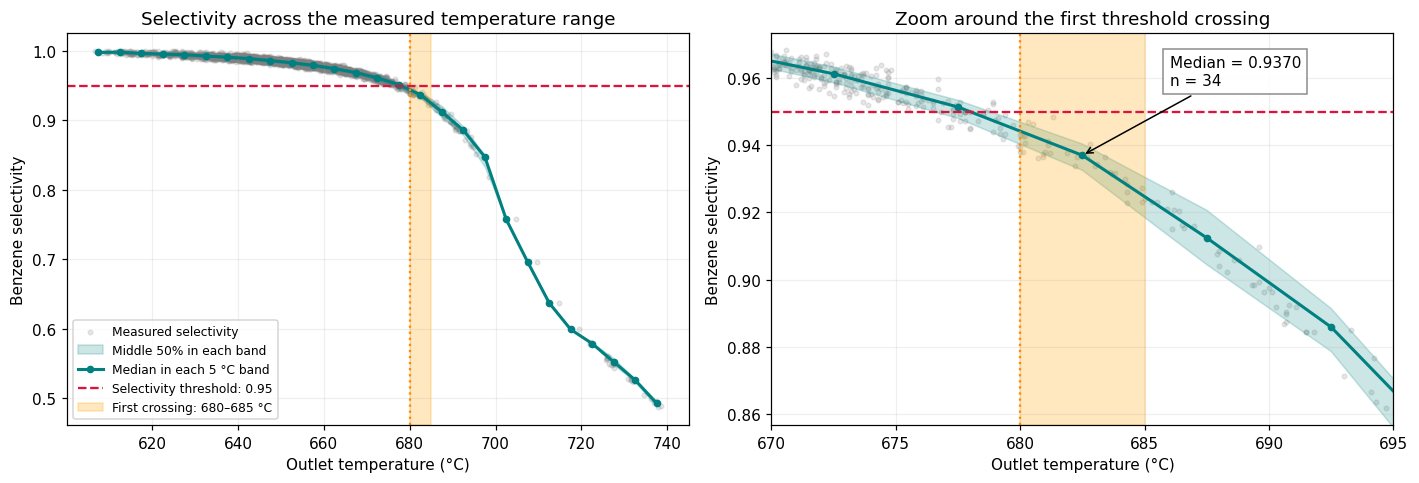

In [ ]:
v = (df_corrected[["T_out_C", "S_benz"]]
     .replace([np.inf, -np.inf], np.nan).dropna())

edges = np.arange(np.floor(v.T_out_C.min() / 5) * 5,
                  np.floor(v.T_out_C.max() / 5) * 5 + 10, 5)
groups = v.groupby(
    pd.cut(v.T_out_C, edges, right=False), observed=True
).S_benz

s = groups.agg(
    Readings="size", Median="median",
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
)
s["T_mid"] = [band.mid for band in s.index]

crossings = s[s.Median < 0.95]
if crossings.empty:
    raise ValueError("No temperature band has median selectivity below 0.95.")

onset_bin = crossings.index[0]
hydrocracking_onset = float(onset_bin.left)
near = s[s.T_mid.between(onset_bin.left - 10, onset_bin.right + 10)]

print(f"First band below 0.95: {onset_bin.left:g} ≤ T_out < {onset_bin.right:g} °C")
print(f"Median selectivity: {s.loc[onset_bin, 'Median']:.4f} | "
      f"Readings: {int(s.loc[onset_bin, 'Readings'])}")
print(f"For later checks, I use the lower edge: {hydrocracking_onset:g} °C.")
display(near.drop(columns="T_mid").round(4))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

for ax in axs:
    ax.scatter(v.T_out_C, v.S_benz, s=9, alpha=0.18,
               color="grey", label="Measured selectivity")
    ax.fill_between(
        s.T_mid.to_numpy(), s.Q1.to_numpy(), s.Q3.to_numpy(),
        color="teal", alpha=0.2, label="Middle 50% in each band"
    )
    ax.plot(s.T_mid, s.Median, "o-", color="teal",
            lw=2, ms=4, label="Median in each 5 °C band")
    ax.axhline(0.95, color="crimson", ls="--",
               label="Selectivity threshold: 0.95")
    ax.axvspan(
        onset_bin.left, onset_bin.right, color="orange", alpha=0.25,
        label=f"First crossing: {onset_bin.left:g}–{onset_bin.right:g} °C"
    )
    ax.axvline(hydrocracking_onset, color="darkorange", ls=":")
    ax.set(xlabel="Outlet temperature (°C)", ylabel="Benzene selectivity")
    ax.grid(alpha=0.2)

axs[0].set_title("Selectivity across the measured temperature range")
axs[0].legend(loc="lower left", fontsize=8)

axs[1].set_title("Zoom around the first threshold crossing")
axs[1].set_xlim(onset_bin.left - 10, onset_bin.right + 10)
zoom = v[v.T_out_C.between(onset_bin.left - 10, onset_bin.right + 10)]
axs[1].set_ylim(
    max(0, zoom.S_benz.min() - 0.005),
    min(1.01, zoom.S_benz.max() + 0.005)
)
axs[1].annotate(
    f"Median = {s.loc[onset_bin, 'Median']:.4f}\n"
    f"n = {int(s.loc[onset_bin, 'Readings'])}",
    xy=(onset_bin.mid, s.loc[onset_bin, "Median"]),
    xytext=(onset_bin.right + 1, 0.958),
    arrowprops=dict(arrowstyle="->", color="black"),
    bbox=dict(facecolor="white", edgecolor="grey", alpha=0.9)
)

plt.tight_layout()
plt.show()

**C**

I obtained different optimum inlet temperatures because conversion and benzene production have different targets:

| Model objective | Inlet temperature | Predicted conversion | Predicted benzene production |
|---|---:|---:|---:|
| Maximum conversion | 666 °C | 99.2% | 75.02 kmol/h |
| Maximum benzene production | 624 °C | 93.9% | 110.46 kmol/h |

Selectivity is the fraction of converted toluene that becomes benzene:

$$
S=\frac{B}{FX},
\qquad
B=FXS
$$

At higher temperatures, conversion increases but selectivity falls because more unwanted products form. Therefore, the extra conversion does not necessarily increase benzene production. I find that **624 °C gives the best predicted balance between conversion and selectivity** based on the results ML gives.

To estimate hydrocracking onset, I grouped measured outlet temperatures into **5 K-wide bands** and found the first band where median selectivity fell below **0.95**:

| Outlet-temperature band | Readings | Median selectivity |
|---|---:|---:|
| 675–680 °C | 69 | 0.9514 |
| 680–685 °C | 34 | **0.9370** |

I therefore identify **680–685 °C as the observed onset band**, using the assignment’s selectivity criterion.

For later design checks, I adopt **675 °C as a conservative assumed onset**, 5 °C below the observed band’s lower edge. This is a design assumption, rather than the measured threshold.

In [ ]:
hydrocracking_onset = 675.0
outlet_limit = hydrocracking_onset - 10
heater_limit = 0.90 * 3500

search = pd.DataFrame([
    check_point(float(T), onset=hydrocracking_onset)[0]
    for T in np.round(np.arange(585, 700.01, 0.1), 1)
])
allowed = search[
    (search.T_out <= outlet_limit) & (search.duty_kW <= heater_limit)
]
if allowed.empty:
    raise ValueError("No tested temperature meets both requirements.")

bestD = allowed.loc[allowed.T_in.idxmax()]

sel = (df_corrected[["T_out_C", "S_benz"]]
       .replace([np.inf, -np.inf], np.nan).dropna())
sel_curve = sel.groupby(
    np.floor(sel.T_out_C / 5) * 5 + 2.5
).S_benz.median()

comparison = {}
for label, T in [("Baseline", 600.0), ("Selected", float(bestD.T_in))]:
    res, _ = check_point(T, onset=hydrocracking_onset)
    S = float(np.interp(
        res["T_out"], sel_curve.index.to_numpy(), sel_curve.to_numpy()
    ))
    comparison[label] = {
        "Inlet temperature (°C)": T,
        "Outlet temperature (°C)": res["T_out"],
        "Heater duty (kW)": res["duty_kW"],
        "Conversion": res["X_physics"],
        "Assumed selectivity": S,
        "Benzene (kmol/h)": res["F_kmolh"] * res["X_physics"] * S
    }

comparison = pd.DataFrame(comparison)
benzene_gain = (comparison.loc["Benzene (kmol/h)", "Selected"]
                - comparison.loc["Benzene (kmol/h)", "Baseline"])
gain_percent = 100 * benzene_gain / comparison.loc["Benzene (kmol/h)", "Baseline"]
next_point, _ = check_point(float(bestD.T_in) + 0.1, onset=hydrocracking_onset)

print(f"Required: outlet ≤ {outlet_limit:.1f} °C; heater duty ≤ {heater_limit:.0f} kW")
print(f"Highest tested inlet meeting both: {bestD.T_in:.1f} °C")
print(f"At {next_point['T_in']:.1f} °C inlet, outlet = {next_point['T_out']:.3f} °C")
display(comparison.round(4))
print(f"Benzene gain: {benzene_gain:.2f} kmol/h ({gain_percent:.1f}%)")

Required: outlet ≤ 665.0 °C; heater duty ≤ 3150 kW
Highest tested inlet meeting both: 613.6 °C
At 613.7 °C inlet, outlet = 665.024 °C


,Baseline,Selected
Inlet temperature (°C),600.0000,613.6000
Outlet temperature (°C),641.2369,664.8695
Heater duty (kW),2433.1290,2521.3705
Conversion,0.7037,0.8749
Assumed selectivity,0.9896,0.9719
Benzene (kmol/h),86.4034,105.5026


Benzene gain: 19.10 kmol/h (22.1%)


**D**

I use my asumption of hydrocracking onset of **675 °C**. The required limits are:

$$
T_{\mathrm{out}}\le675-10=\boxed{665^\circ\mathrm C}
$$

$$
Q_{\mathrm{H101}}\le0.90(3500)=\boxed{3150\ \mathrm{kW}}
$$

At my median pressure, hydrogen ratio and feed rate, I searched inlet temperatures in **0.1 °C steps**. The highest tested temperature meeting both requirements is **613.6 °C**.

| Quantity | Baseline: 600 °C inlet | Selected: 613.6 °C inlet |
|---|---:|---:|
| Predicted outlet temperature, °C | 641.24 | 664.87 |
| Heater duty, kW | 2433.13 | 2521.37 |
| Conversion | 0.7037 | 0.8749 |
| Assumed selectivity | 0.9896 | 0.9719 |
| Benzene production, kmol/h | 86.40 | 105.50 |

I assume selectivity follows the measured median selectivity-versus-outlet-temperature trend, interpolated between 5 °C-band centres.

Using $B=FXS$, the predicted benzene gain is:

$$
\Delta B=105.50-86.40
=\boxed{19.10\ \mathrm{kmol/h}}
$$

$$
\%\text{ gain}=\frac{19.10}{86.40}\times100
\approx\boxed{22.1\%}
$$

The outlet-temperature requirement controls my selection: the next tested inlet temperature, **613.7 °C**, predicts an outlet of **665.024 °C**, just above the permitted value.

## Step 10 · Recommendation to the plant manager
### ❓ Q6 · Technical memo (graded, 15 %)
Write a memo of **at most 200 words** answering the manager's two questions. It must contain:
* exactly **three numbers** from your analysis, each followed by the step/cell that produced it, e.g. *"(Step 5)"*;
* one **condition of special concern** and its justification or penalty (Ch. 6 language);
* one limitation of your data or model, and what extra data would remove it.

✏️ **Your memo:**

Using analyser-corrected data, I find benzene production depends on conversion and selectivity, affected by temperature, pressure, hydrogen ratio and calculated residence time. Correlated pressure and hydrogen ratio complicate ML importance.

My graphs and calculations show warmer cooling water raises flash temperature, benzene vapour pressure and purge losses. Warmest-month mean loss was **1.85 times** (Step 8) the coldest-month loss. I would assess chilled-water cooling against equipment and electricity costs.

I reject conversion-maximising operation because its predicted outlet temperature exceeds the design limit. I recommend a controlled trial at **613.6 °C** (Step 9), meeting my temperature and heater-duty margins at median conditions, with a predicted benzene gain of **22.1%** (Step 9) over baseline.

High-temperature operation is a condition of special concern: it increases reaction rate and conversion but requires suitable materials and temperature protection, increasing costs. Excessive heating reduces selectivity. Pressure above the easy operating range increases concentration and residence time without shifting ideal-gas equilibrium.

I assume the measured selectivity trend applies at the proposed conditions. Controlled trials at fixed pressure, hydrogen ratio and feed, with laboratory benzene/by-product measurements, would test this assumption and the hydrocracking onset inferred from selectivity in temperature bands.

### ❓ Q7 · Transfer question (graded, 5 %)
The manager now asks to **lower** the reactor pressure from your median value to 15 barg to save compressor power. Without running new code, predict qualitatively — with the equation that supports each statement — the effect on (i) residence time, (ii) conversion, (iii) benzene loss at V-102, (iv) the H₂/toluene policy. Then run `check_point(T, P=15)` at your recommended T_in and state whether your predictions were right.

✏️ **Your answer:**


**i**

I predict that residence time decreases:

$$
Q=\frac{F(1+r)}{3600}\frac{RT_{\mathrm{eff}}}{P_{\mathrm{abs}}},
\qquad
\tau=\frac{V_R}{Q}
$$

At constant temperature, feed and hydrogen ratio, lower pressure increases $Q$. Therefore, $\tau$ decreases.

**ii**

I predict that conversion decreases:

$$
X=1-\exp\left[-k(T)\tau\sqrt{p_{H_2}}\right]
$$

$$
p_{H_2}=\frac{P_{\mathrm{abs}}}{100}\frac{r}{1+r}
$$

Lower pressure reduces residence time, giving less time to react. It also reduces hydrogen partial pressure, slowing the reaction. Both effects lower conversion.

**iii**

I predict that benzene loss tends to increase if flash pressure follows the relationship observed in my corrected data:

$$
P_{\mathrm{flash,barg}}\approx P_{\mathrm{reactor,barg}}-1.40
$$

Reducing reactor pressure from 24.8 to 15 barg would therefore reduce flash pressure from approximately 23.4 to 13.6 barg.

From Raoult’s law:

$$
K_B=\frac{P_B^{sat}}{P_{\mathrm{flash,abs}}},
\qquad
y_B=K_Bx_B
$$

At unchanged flash temperature and liquid composition, lower flash pressure increases $K_B$ and the benzene fraction in the purge gas. With unchanged purge-gas molar flow, benzene loss increases.

**iv**

My fitted operating-policy equation from Step 7 is:

$$
r=0.6148P-10.5215
$$

At 15 barg:

$$
r=0.6148(15)-10.5215=\boxed{-1.2995}
$$

The fitted trend suggests that hydrogen ratio decreases with pressure, but a negative molar ratio is physically impossible.

I therefore cannot apply this policy line at 15 barg. This pressure is outside my recorded range of approximately **22.35–27.02 barg**, so the relationship is unsuitable for this extrapolation. I would need to establish a suitable positive hydrogen ratio separately.

In [ ]:
# @markdown Running check_point(T, P)
T_recommended = float(bestD.T_in)
results = {}

for label, P in [("Median pressure", float(med.P_R_barg)), ("15 barg", 15.0)]:
    res, pcm = check_point(T_recommended, P=P, onset=675.0)
    T_eff = (res["T_in"] + res["T_out"]) / 2 + 273.15
    P_abs = 100 * res["P_barg"] + 101.325
    Q = res["F_kmolh"] * (1 + res["r"]) / 3600 * 8.314 * T_eff / P_abs

    results[label] = {
        "Reactor pressure (barg)": res["P_barg"],
        "Effective temperature (K)": T_eff,
        "Residence time (s)": 40 / Q,
        "Hydrogen partial pressure (bar)": (
            P_abs / 100 * res["r"] / (1 + res["r"])
        ),
        "Conversion (%)": 100 * res["X_physics"],
        "Outlet temperature (°C)": res["T_out"],
        "Heater duty (kW)": res["duty_kW"]
    }

comparison_q7 = pd.DataFrame(results)
print(f"Inlet temperature: {T_recommended:.1f} °C")
print(f"H₂/toluene ratio fixed at {med.H2_tol_ratio:.4f}; "
      f"feed fixed at {med.F_tol_kmolh:.2f} kmol/h.")
display(comparison_q7.round(4))

for quantity in ["Residence time (s)", "Conversion (%)"]:
    old = comparison_q7.loc[quantity, "Median pressure"]
    new = comparison_q7.loc[quantity, "15 barg"]
    verdict = "confirmed" if new < old else "not confirmed"
    print(f"{quantity}: {old:.4f} → {new:.4f}; "
          f"predicted decrease {verdict}.")

print("Flash loss is not calculated by check_point; prediction (iii) remains conditional.")
print("The hydrogen-ratio policy is not extrapolated; the median ratio is held fixed.")

Inlet temperature: 613.6 °C
H₂/toluene ratio fixed at 4.7050; feed fixed at 124.07 kmol/h.


,Median pressure,15 barg
Reactor pressure (barg),24.8000,15.0000
Effective temperature (K),912.3847,902.4053
Residence time (s),69.2301,43.4218
Hydrogen partial pressure (bar),21.2886,13.2064
Conversion (%),87.4934,53.4327
Outlet temperature (°C),664.8695,644.9105
Heater duty (kW),2521.3705,2521.3705


Residence time (s): 69.2301 → 43.4218; predicted decrease confirmed.
Conversion (%): 87.4934 → 53.4327; predicted decrease confirmed.
Flash loss is not calculated by check_point; prediction (iii) remains conditional.
The hydrogen-ratio policy is not extrapolated; the median ratio is held fixed.


---
### AI-use declaration (required)
You may use AI tools to help with Python syntax. You may **not** paste your answers' reasoning from an AI tool. State below: which tool(s), for which cells, and one thing the tool got wrong or could not know about your dataset. *You may be asked to explain any of your answers orally in 3 minutes, using your own notebook.*

✏️ **Declaration:**

I used OpenAI's **GPT-6.1 Sol at High effort** for all the code within this jupyter notebook and expressions written in LaTeX in Markdown cells. It couldn't establish the relationships and I often had to direct it. For example, in the final question, it didn't notice that there was an empirical connection between pressure in reactor and flash pressure.

*(write here)*